# 04_sensor_response_analysis
Phase 1 보고서와 원자료 기반 감사 결과. 전체 재계산: 프로젝트 루트에서 `./run_phase1.ps1`.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'reports').exists(): ROOT = ROOT.parent
display(Markdown((ROOT / 'reports/markdown/04_fault_sensor_response.md').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT / 'reports/tables/a_fault_response.csv').head(60))


# 고장별 센서 반응

## 방법과 해석 범위

Mode 1 정상 50h 중 t≥5h를 기술통계 참조로 사용했다. 5h 제외는 초기 과도 영향을 줄이기 위한 분석 선택이다. 모델 전처리 학습이나 경보 임계값 최적화가 아니다. 고장별 t≥10h(모델 명목 주입 이후) 평균을 정상 평균/표준편차로 표준화했고 같은 Fault 내 완전히 동일한 시계열을 하나로 세어 실행별 평균에 동일 가중치를 주었다. 다른 고장 간 중복은 별도 검사했다. 기준 정상 실행이 하나여서 신뢰구간과 인과 추론을 제공하지 않는다.

상관관계 차이(t≥5h 전체)와 대표 run 1의 시계열, 정상 대비 편차, 명목 주입 전 5~10h/후 10h~ 비교 및 지속 편차 최초 확인 시각을 각 Fault에 대해 생성했다. 서로 다른 단위 원시 시계열은 크기를 직접 비교할 수 없다. 단위 비교는 z 패널을 사용한다.

고장 주입 시각은 Excel에 없다. 배포 모델 배선을 확인하면 Constant dist(SID 3)가 VariableTransportDelay(SID 250)를 지나 TE Plant 입력 13으로 들어가고, Constant 10(SID 249)이 지연 입력에 연결된다. 따라서 **배포 모델의 명목 주입은 10h**다. auto_run.m에서 dist를 미리 설정하는 것과 실제 Plant 적용 시각은 다르다. 시계열에서 10h 이후 변화와 일치하는 사례가 있지만 모든 파일의 생성 시점 모델과 idv 로그는 없으므로 10h를 파일별 확정 사실로 취급하지 않았다. 그림의 점선은 이 명목 기준이다.

지속 편차 시각은 30개 trailing 평균의 |z|>3이 10개 연속 관찰된 확인 시각(t≥10h 검색)이다. 10번째 샘플에서 경보를 확인하도록 시간을 기록했다. 명목 10h 대비 차이를 a_deviation_onsets.csv에 분 단위로 제공하지만 주입 시각이 검증된 실제 탐지 지연으로 해석하면 안 된다. 명목 경계부터 조건을 만족하면 이전 반응은 좌측 검열된다. 이 고정 기술통계 규칙을 Phase 2 경보 임계값으로 채택한 것은 아니다.

## 주요 반응 (모델 중요도나 물리 원인이 아님)

| fault | variable | standardized_mean_difference | unique_series |
| --- | --- | --- | --- |
| 1 | xmeas_1 | 90.997 | 6 |
| 1 | xmeas_18 | 10.707 | 6 |
| 1 | xmeas_4 | -9.93 | 6 |
| 2 | xmeas_34 | -51.417 | 6 |
| 2 | xmeas_28 | -40.994 | 6 |
| 2 | xmeas_10 | 19.132 | 6 |
| 3 | xmeas_21 | -1.5271 | 6 |
| 3 | xmeas_30 | 0.3351 | 6 |
| 3 | xmeas_37 | 0.22589 | 6 |
| 4 | xmeas_34 | 0.34121 | 6 |
| 4 | xmeas_30 | 0.29357 | 6 |
| 4 | xmeas_28 | 0.18229 | 6 |
| 5 | xmeas_30 | 0.47049 | 6 |
| 5 | xmeas_20 | -0.31592 | 6 |
| 5 | xmeas_34 | 0.3003 | 6 |
| 6 | xmeas_18 | -146.49 | 7 |
| 6 | xmeas_20 | -120.94 | 7 |
| 6 | xmeas_22 | -68.326 | 7 |
| 7 | xmeas_34 | 0.29153 | 7 |
| 7 | xmeas_37 | 0.21562 | 7 |
| 7 | xmeas_30 | 0.21288 | 7 |
| 8 | xmeas_34 | -3.6049 | 7 |
| 8 | xmeas_28 | -3.073 | 7 |
| 8 | xmeas_18 | -2.8178 | 7 |
| 9 | xmeas_30 | 0.34923 | 7 |
| 9 | xmeas_34 | 0.34157 | 7 |
| 9 | xmeas_18 | -0.28977 | 7 |
| 10 | xmeas_18 | -1.8159 | 9 |
| 10 | xmeas_30 | 0.28365 | 9 |
| 10 | xmeas_34 | 0.21764 | 9 |
| 11 | xmeas_34 | 0.30197 | 9 |
| 11 | xmeas_28 | 0.18837 | 9 |
| 11 | xmeas_37 | 0.17372 | 9 |
| 12 | xmeas_30 | 0.30338 | 9 |
| 12 | xmeas_34 | 0.26329 | 9 |
| 12 | xmeas_18 | -0.20158 | 9 |
| 13 | xmeas_7 | -27.851 | 9 |
| 13 | xmeas_16 | -27.528 | 9 |
| 13 | xmeas_13 | -27.495 | 9 |
| 14 | xmeas_34 | 0.26274 | 9 |
| 14 | xmeas_30 | 0.23285 | 9 |
| 14 | xmeas_37 | 0.18518 | 9 |
| 15 | xmeas_30 | 0.26401 | 9 |
| 15 | xmeas_34 | 0.23435 | 9 |
| 15 | xmeas_37 | 0.16277 | 9 |
| 16 | xmeas_30 | 0.36392 | 9 |
| 16 | xmeas_34 | 0.26584 | 9 |
| 16 | xmeas_38 | 0.17534 | 9 |
| 17 | xmeas_21 | -156.16 | 9 |
| 17 | xmeas_30 | 0.30875 | 9 |
| 17 | xmeas_34 | 0.25413 | 9 |
| 18 | xmeas_22 | -19.173 | 9 |
| 18 | xmeas_30 | 0.30803 | 9 |
| 18 | xmeas_34 | 0.18639 | 9 |
| 19 | xmeas_30 | 0.22553 | 9 |
| 19 | xmeas_21 | -0.19906 | 9 |
| 19 | xmeas_37 | 0.19639 | 9 |
| 20 | xmeas_18 | -19.783 | 8 |
| 20 | xmeas_13 | -18.395 | 8 |
| 20 | xmeas_16 | -14.841 | 8 |
| 21 | xmeas_30 | 0.30543 | 8 |
| 21 | xmeas_34 | 0.212 | 8 |
| 21 | xmeas_18 | -0.20474 | 8 |

![고장별 반응](../figures/fault_response_overview.png)

- [Fault 1 상세 6개 패널](../figures/fault_01_analysis.png)
- [Fault 2 상세 6개 패널](../figures/fault_02_analysis.png)
- [Fault 3 상세 6개 패널](../figures/fault_03_analysis.png)
- [Fault 4 상세 6개 패널](../figures/fault_04_analysis.png)
- [Fault 5 상세 6개 패널](../figures/fault_05_analysis.png)
- [Fault 6 상세 6개 패널](../figures/fault_06_analysis.png)
- [Fault 7 상세 6개 패널](../figures/fault_07_analysis.png)
- [Fault 8 상세 6개 패널](../figures/fault_08_analysis.png)
- [Fault 9 상세 6개 패널](../figures/fault_09_analysis.png)
- [Fault 10 상세 6개 패널](../figures/fault_10_analysis.png)
- [Fault 11 상세 6개 패널](../figures/fault_11_analysis.png)
- [Fault 12 상세 6개 패널](../figures/fault_12_analysis.png)
- [Fault 13 상세 6개 패널](../figures/fault_13_analysis.png)
- [Fault 14 상세 6개 패널](../figures/fault_14_analysis.png)
- [Fault 15 상세 6개 패널](../figures/fault_15_analysis.png)
- [Fault 16 상세 6개 패널](../figures/fault_16_analysis.png)
- [Fault 17 상세 6개 패널](../figures/fault_17_analysis.png)
- [Fault 18 상세 6개 패널](../figures/fault_18_analysis.png)
- [Fault 19 상세 6개 패널](../figures/fault_19_analysis.png)
- [Fault 20 상세 6개 패널](../figures/fault_20_analysis.png)
- [Fault 21 상세 6개 패널](../figures/fault_21_analysis.png)

## 출처와 검증 범위

- Dataset A: https://github.com/Blound04/tennessee-eastman-dataset (MIT). 로컬 README, simulator/auto_run.m, Mode_1_Init.m, MultiLoop_mode1.mdl, TEplot.m, temexd_mod.c를 대조했다. 로컬 checkout의 commit은 미확인이다. 다운로드한 Excel은 원래 LFS 포인터의 SHA256과 일치한다.
- Dataset B: https://doi.org/10.7910/DVN/6C3JR1 . 공식 API의 V1.0 메타데이터를 reports/sources/harvard_metadata.json에 보존했다. 배포 설명은 public-domain dedication과 면책 조건을 포함한다. 로컬 파일의 공식 MD5 일치 여부는 감사 표에 기록했다.
- 수치 결과는 로컬 원본의 재현 가능한 기술통계다. Phase 1에서 모델을 학습하거나 Test로 모델을 선택하지 않았다. 자료는 화학공정 시뮬레이션이며 실제 반도체 공정 검증 결과가 아니다.


,fault,variable,standardized_mean_difference,unique_series,reference,window,causal
0,1,xmeas_1,90.996855,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
1,1,xmeas_2,-0.037107,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
2,1,xmeas_3,-0.097549,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
3,1,xmeas_4,-9.929952,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
4,1,xmeas_5,-0.918565,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
5,1,xmeas_6,-0.932636,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
6,1,xmeas_7,-2.155258,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
7,1,xmeas_8,-0.025246,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
8,1,xmeas_9,-0.003057,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False
9,1,xmeas_10,-0.946102,6,"mode1_normal_50, t>=5h",fault file t>=10h (model nominal injection),False


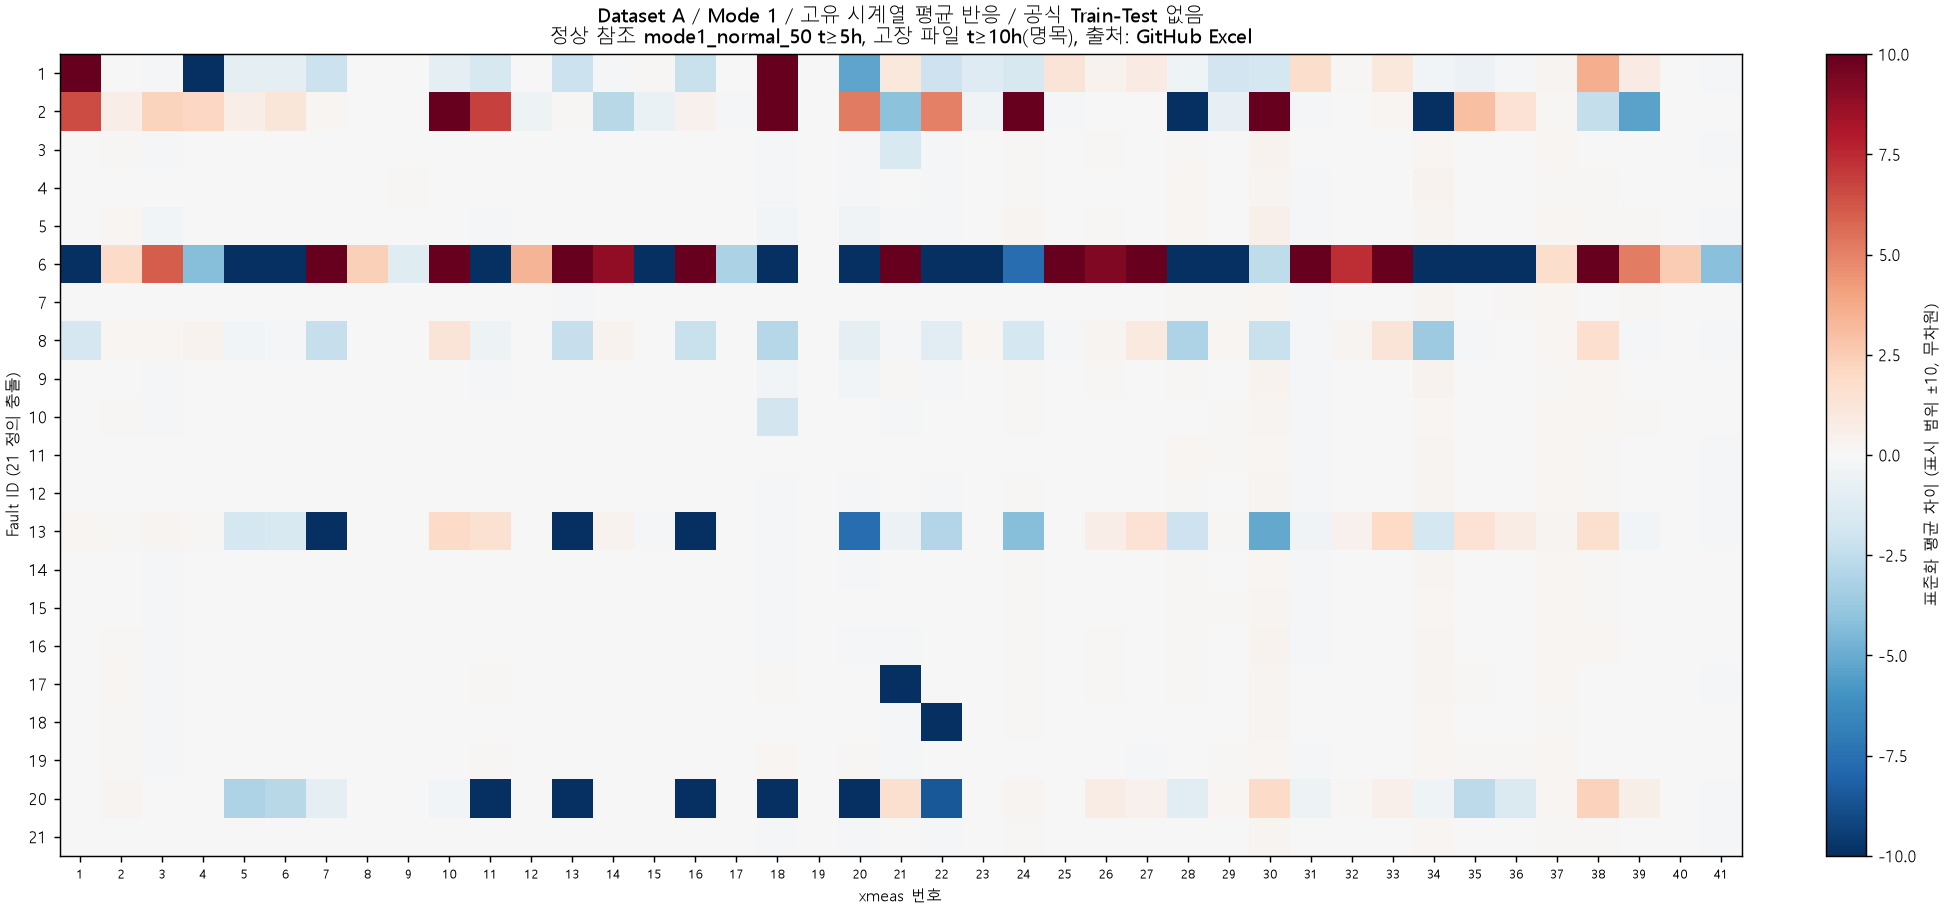

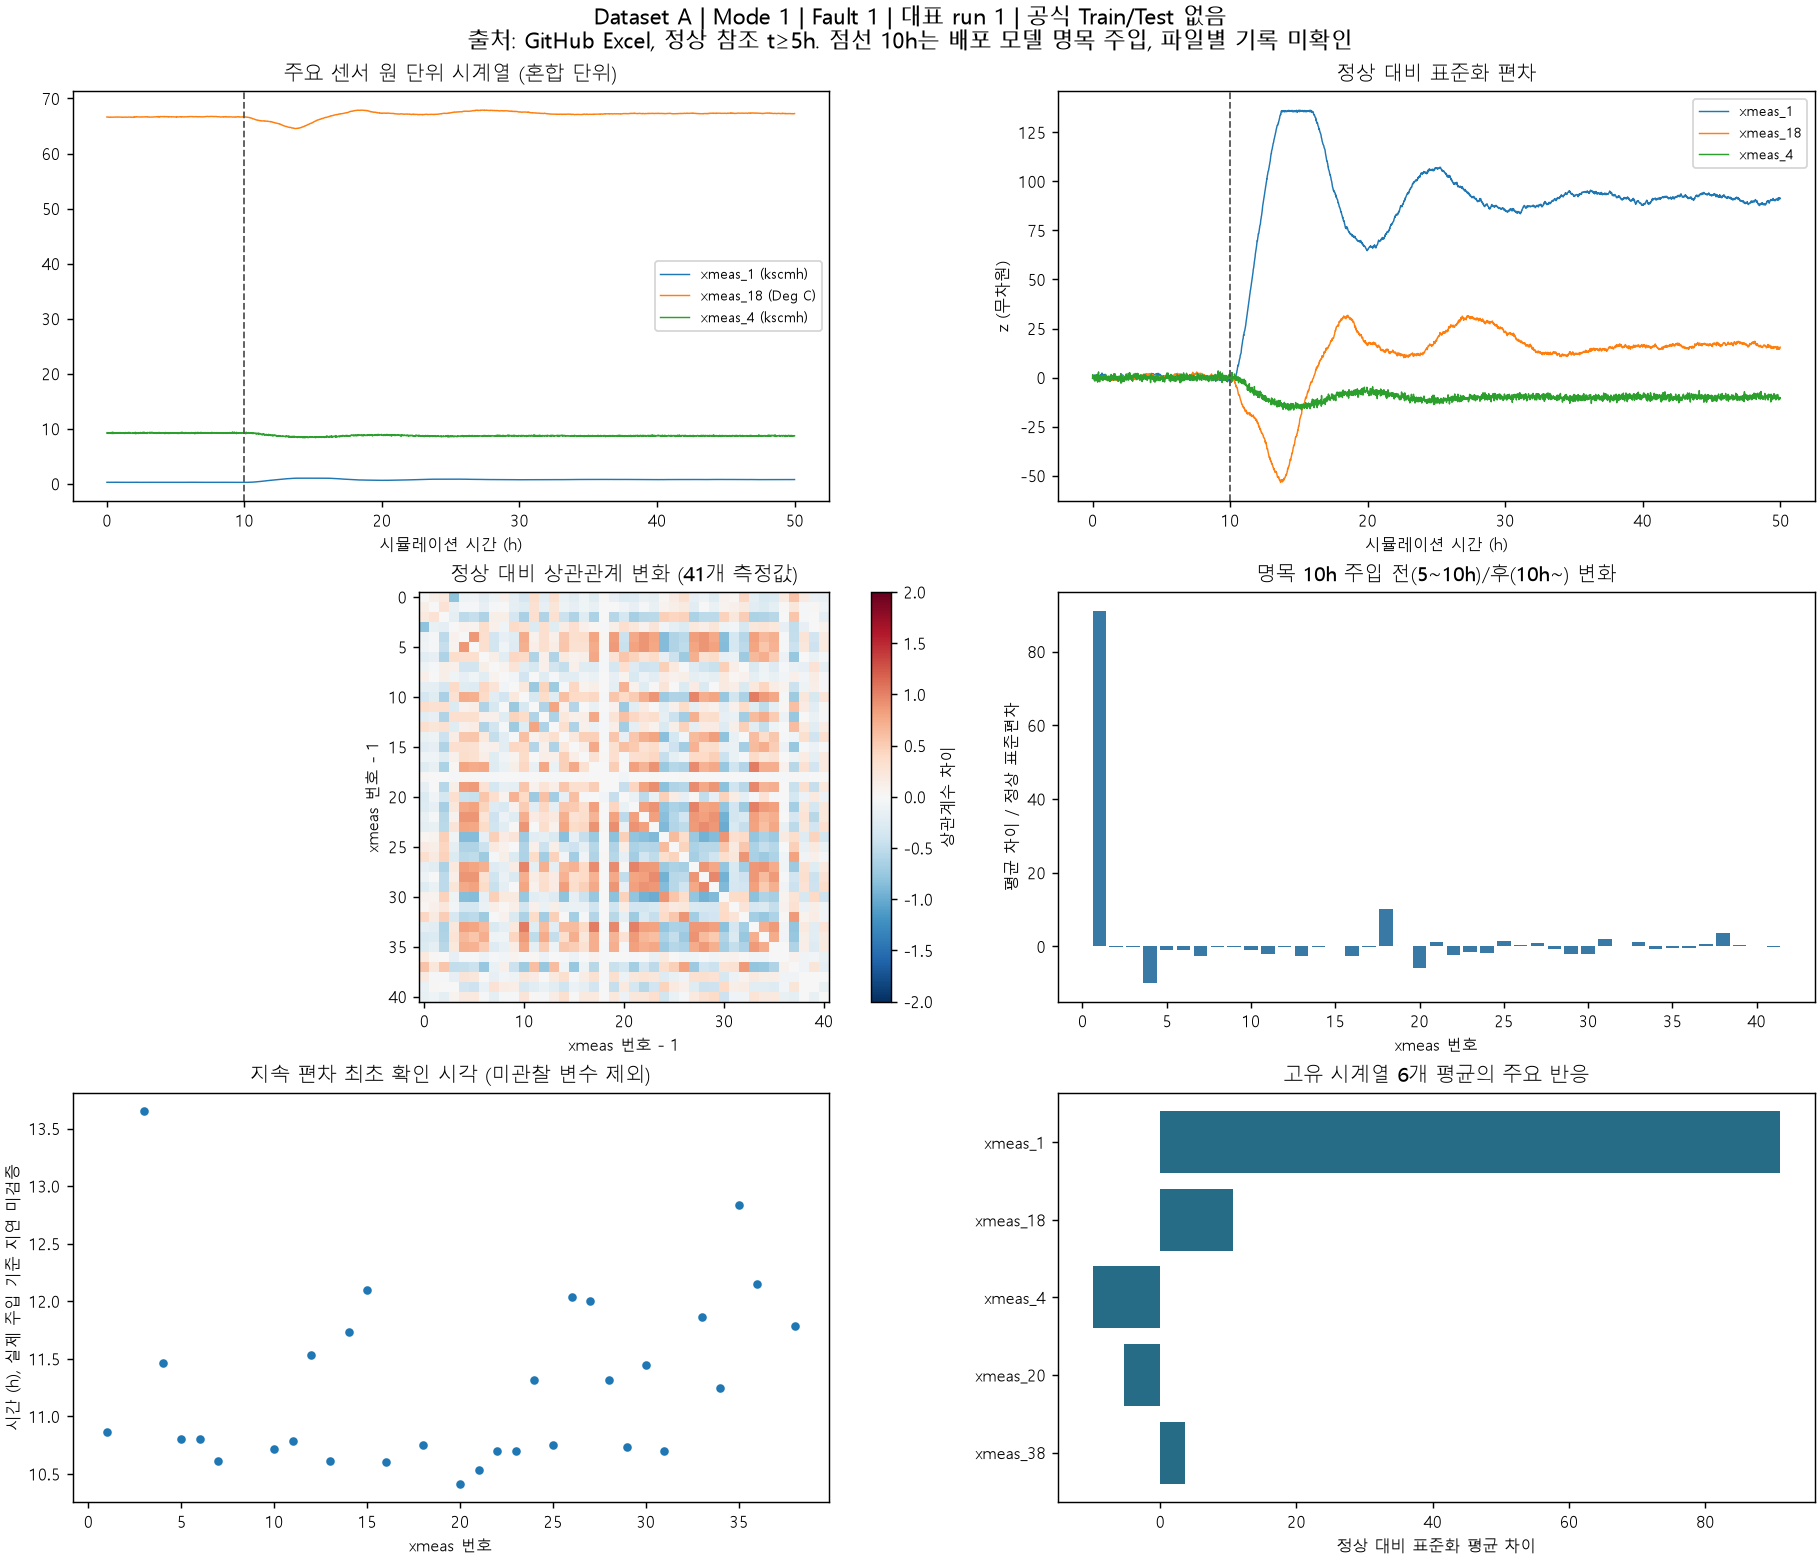

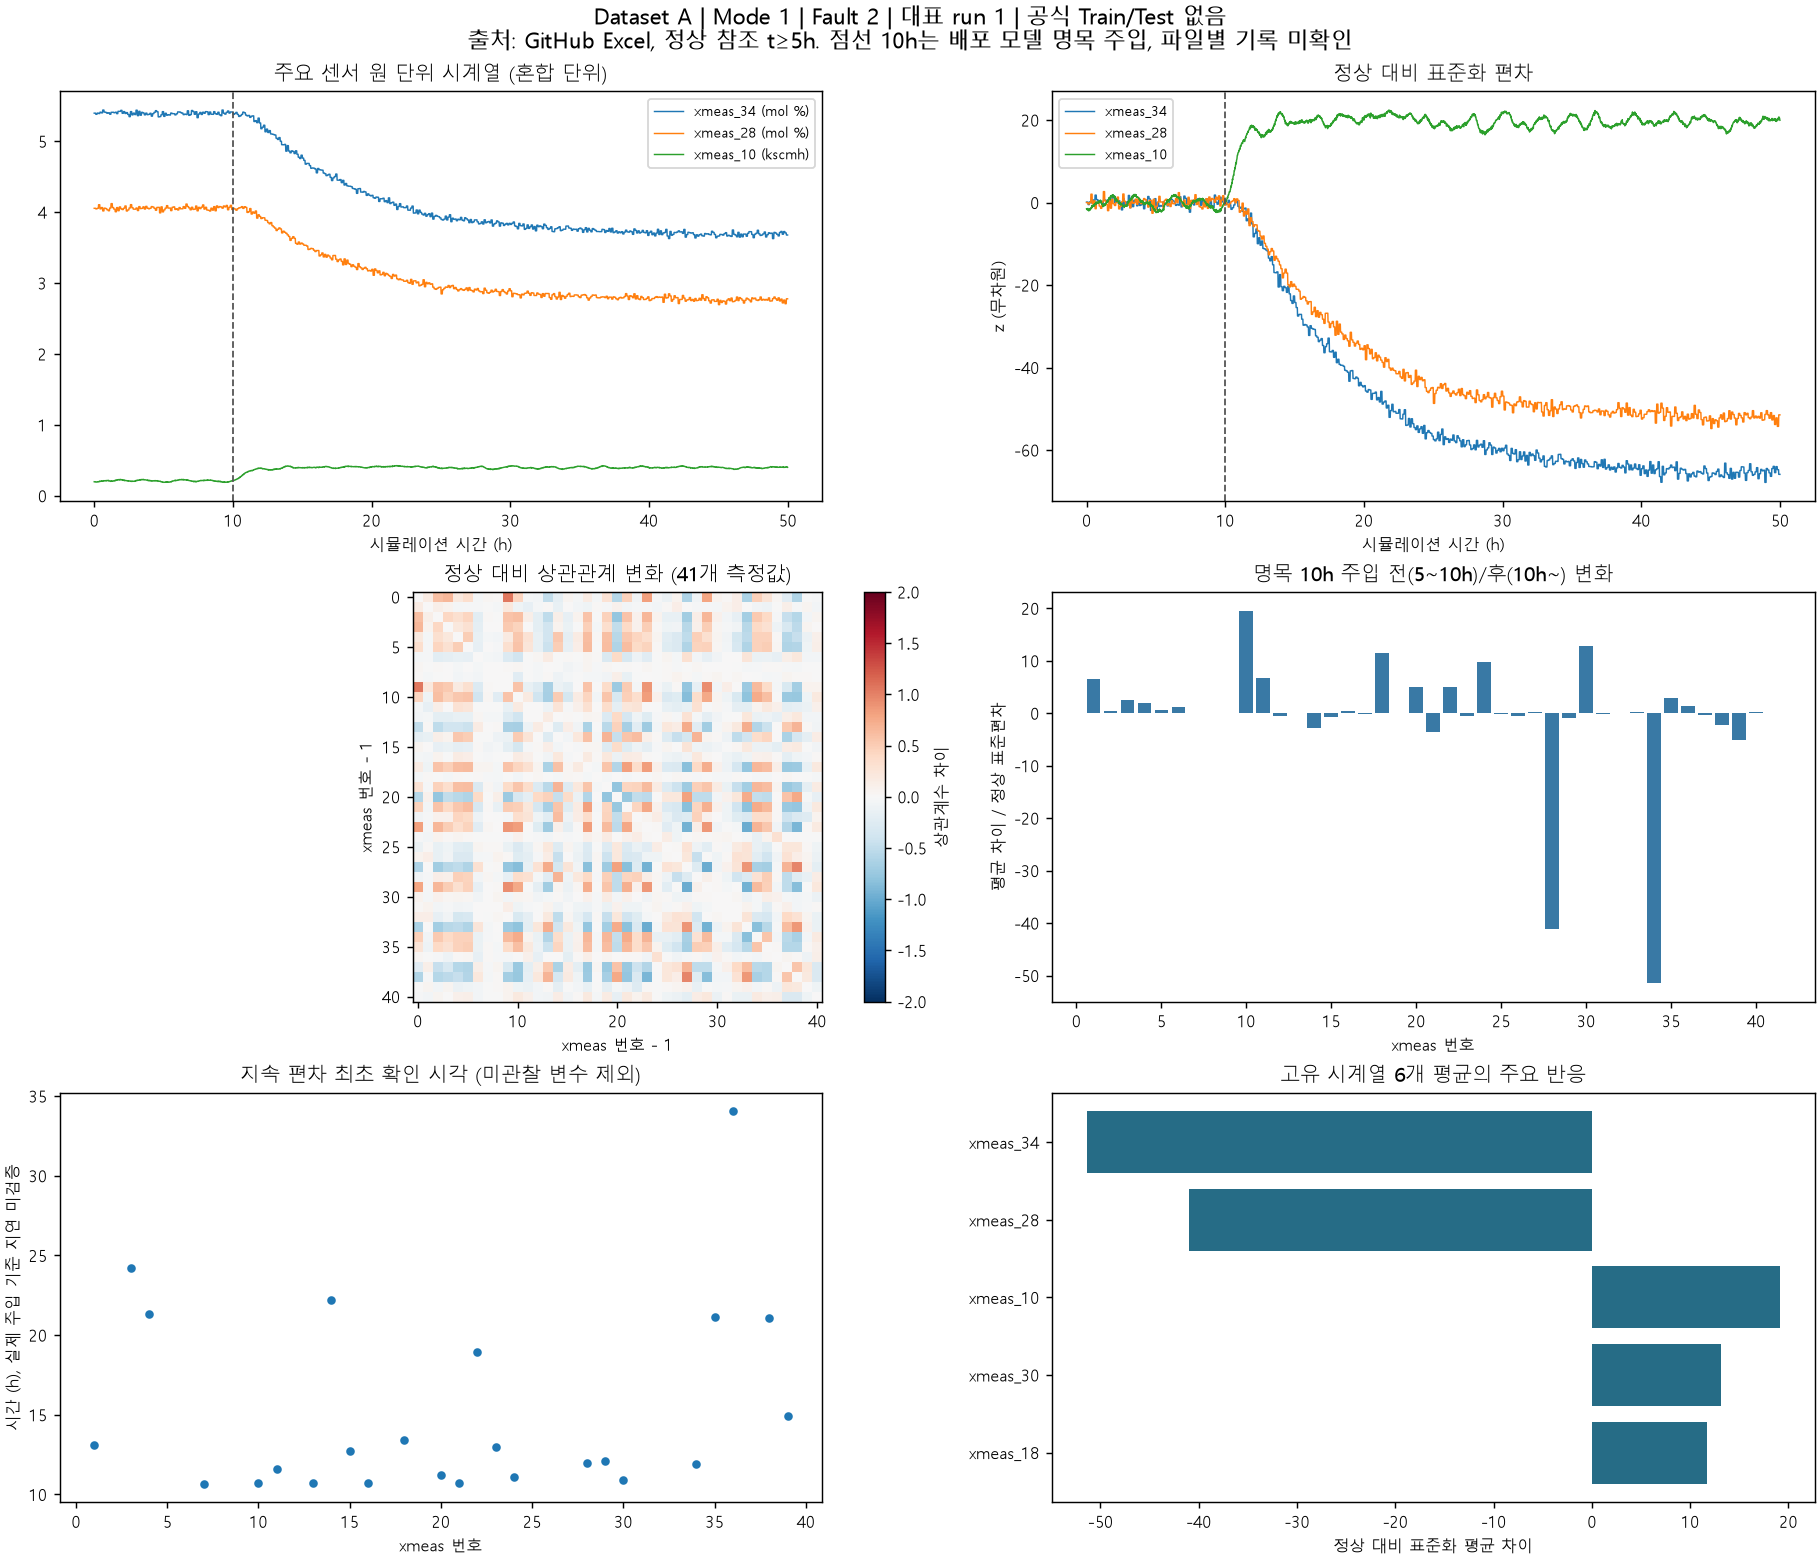

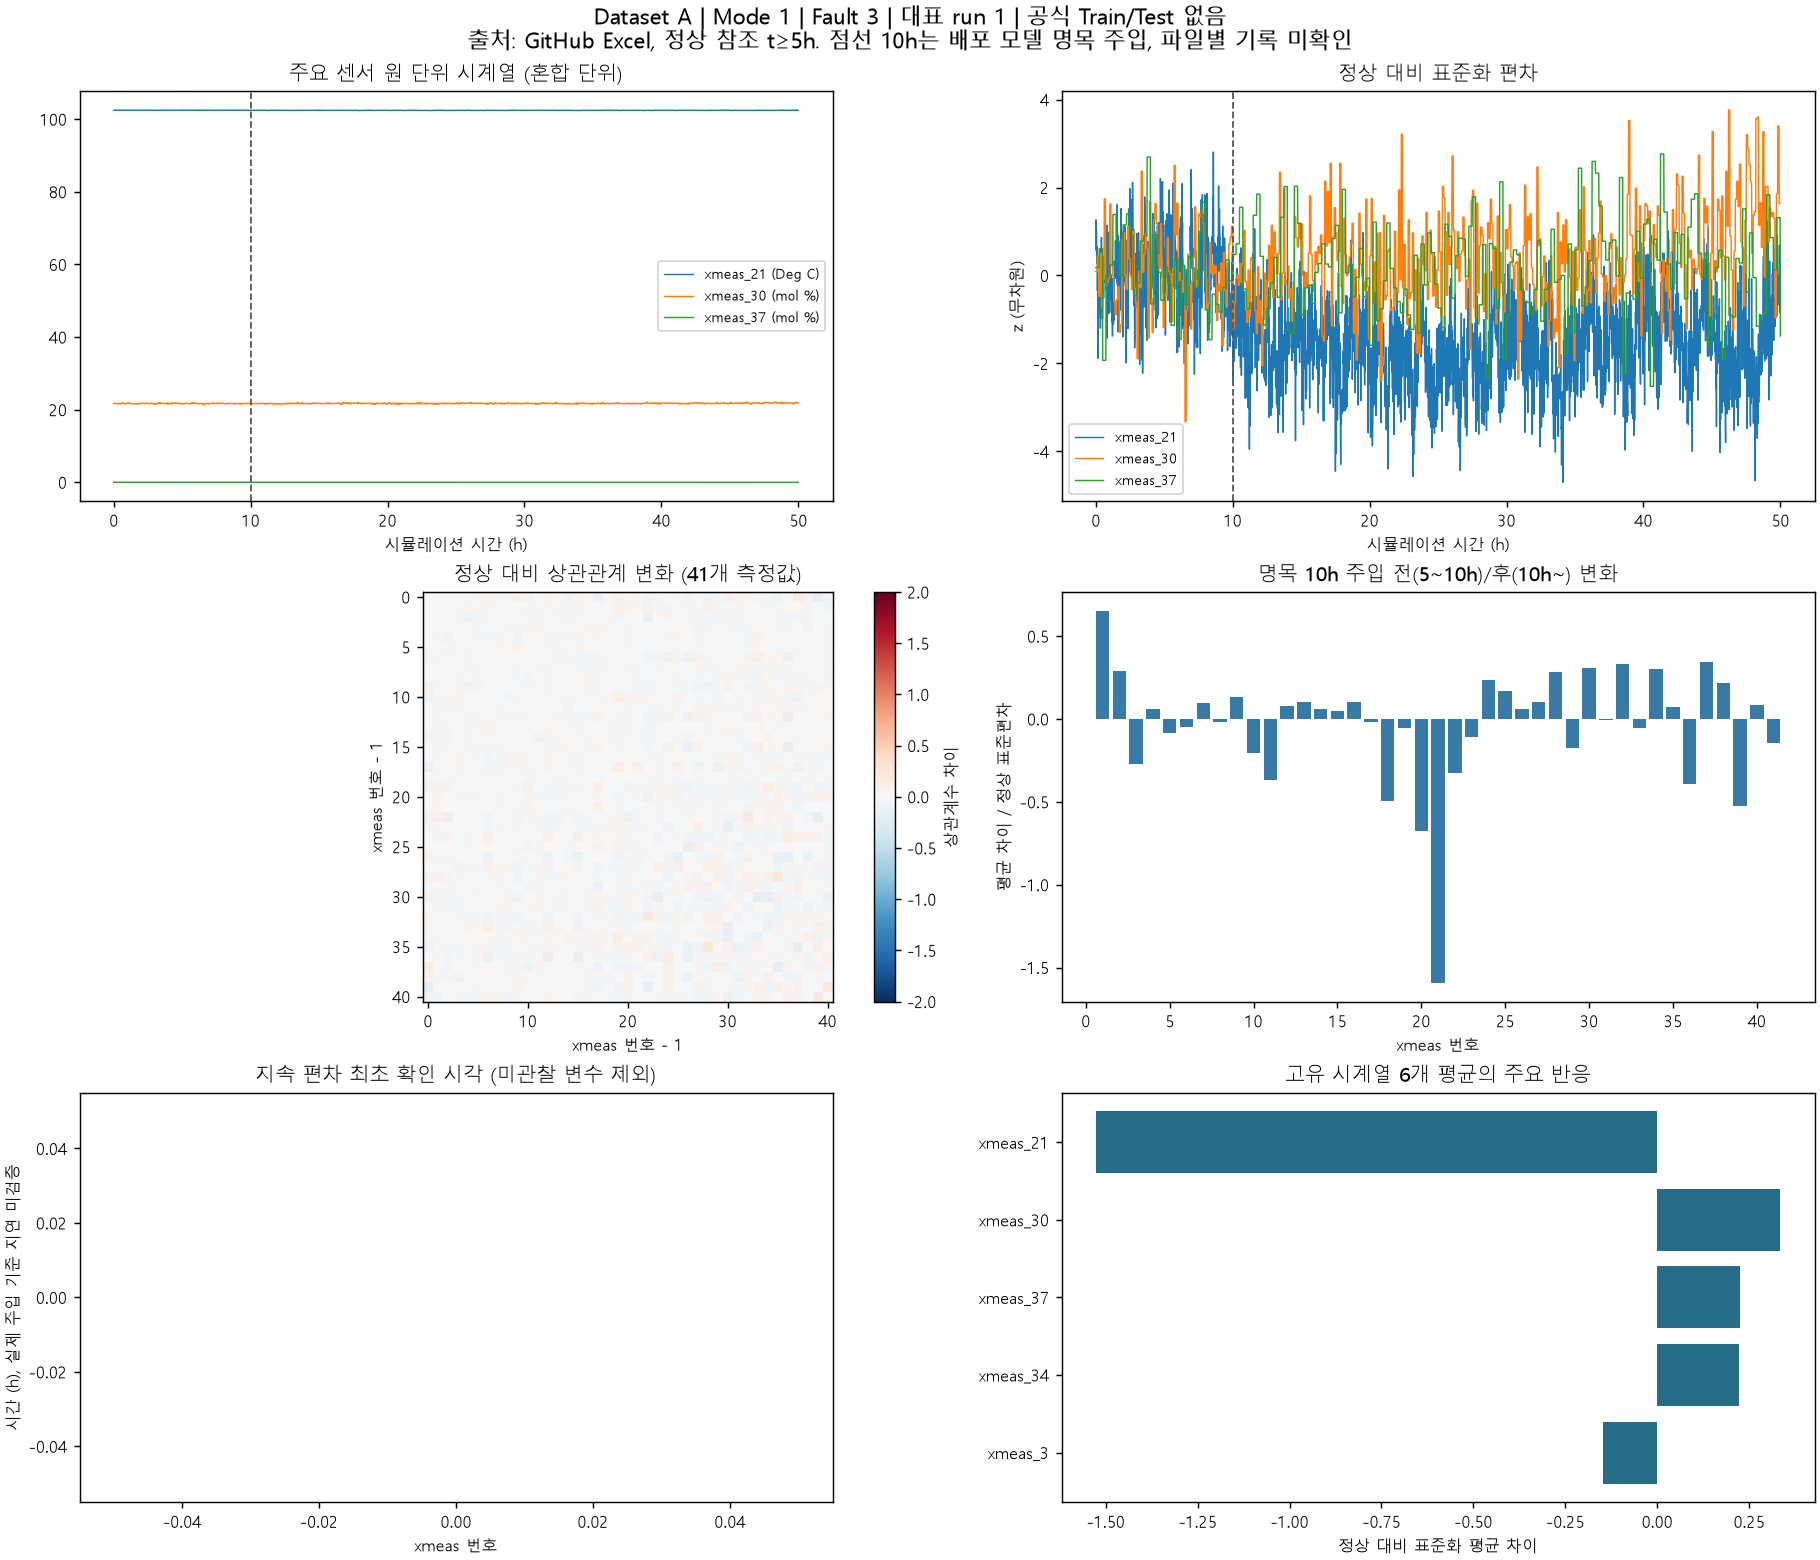

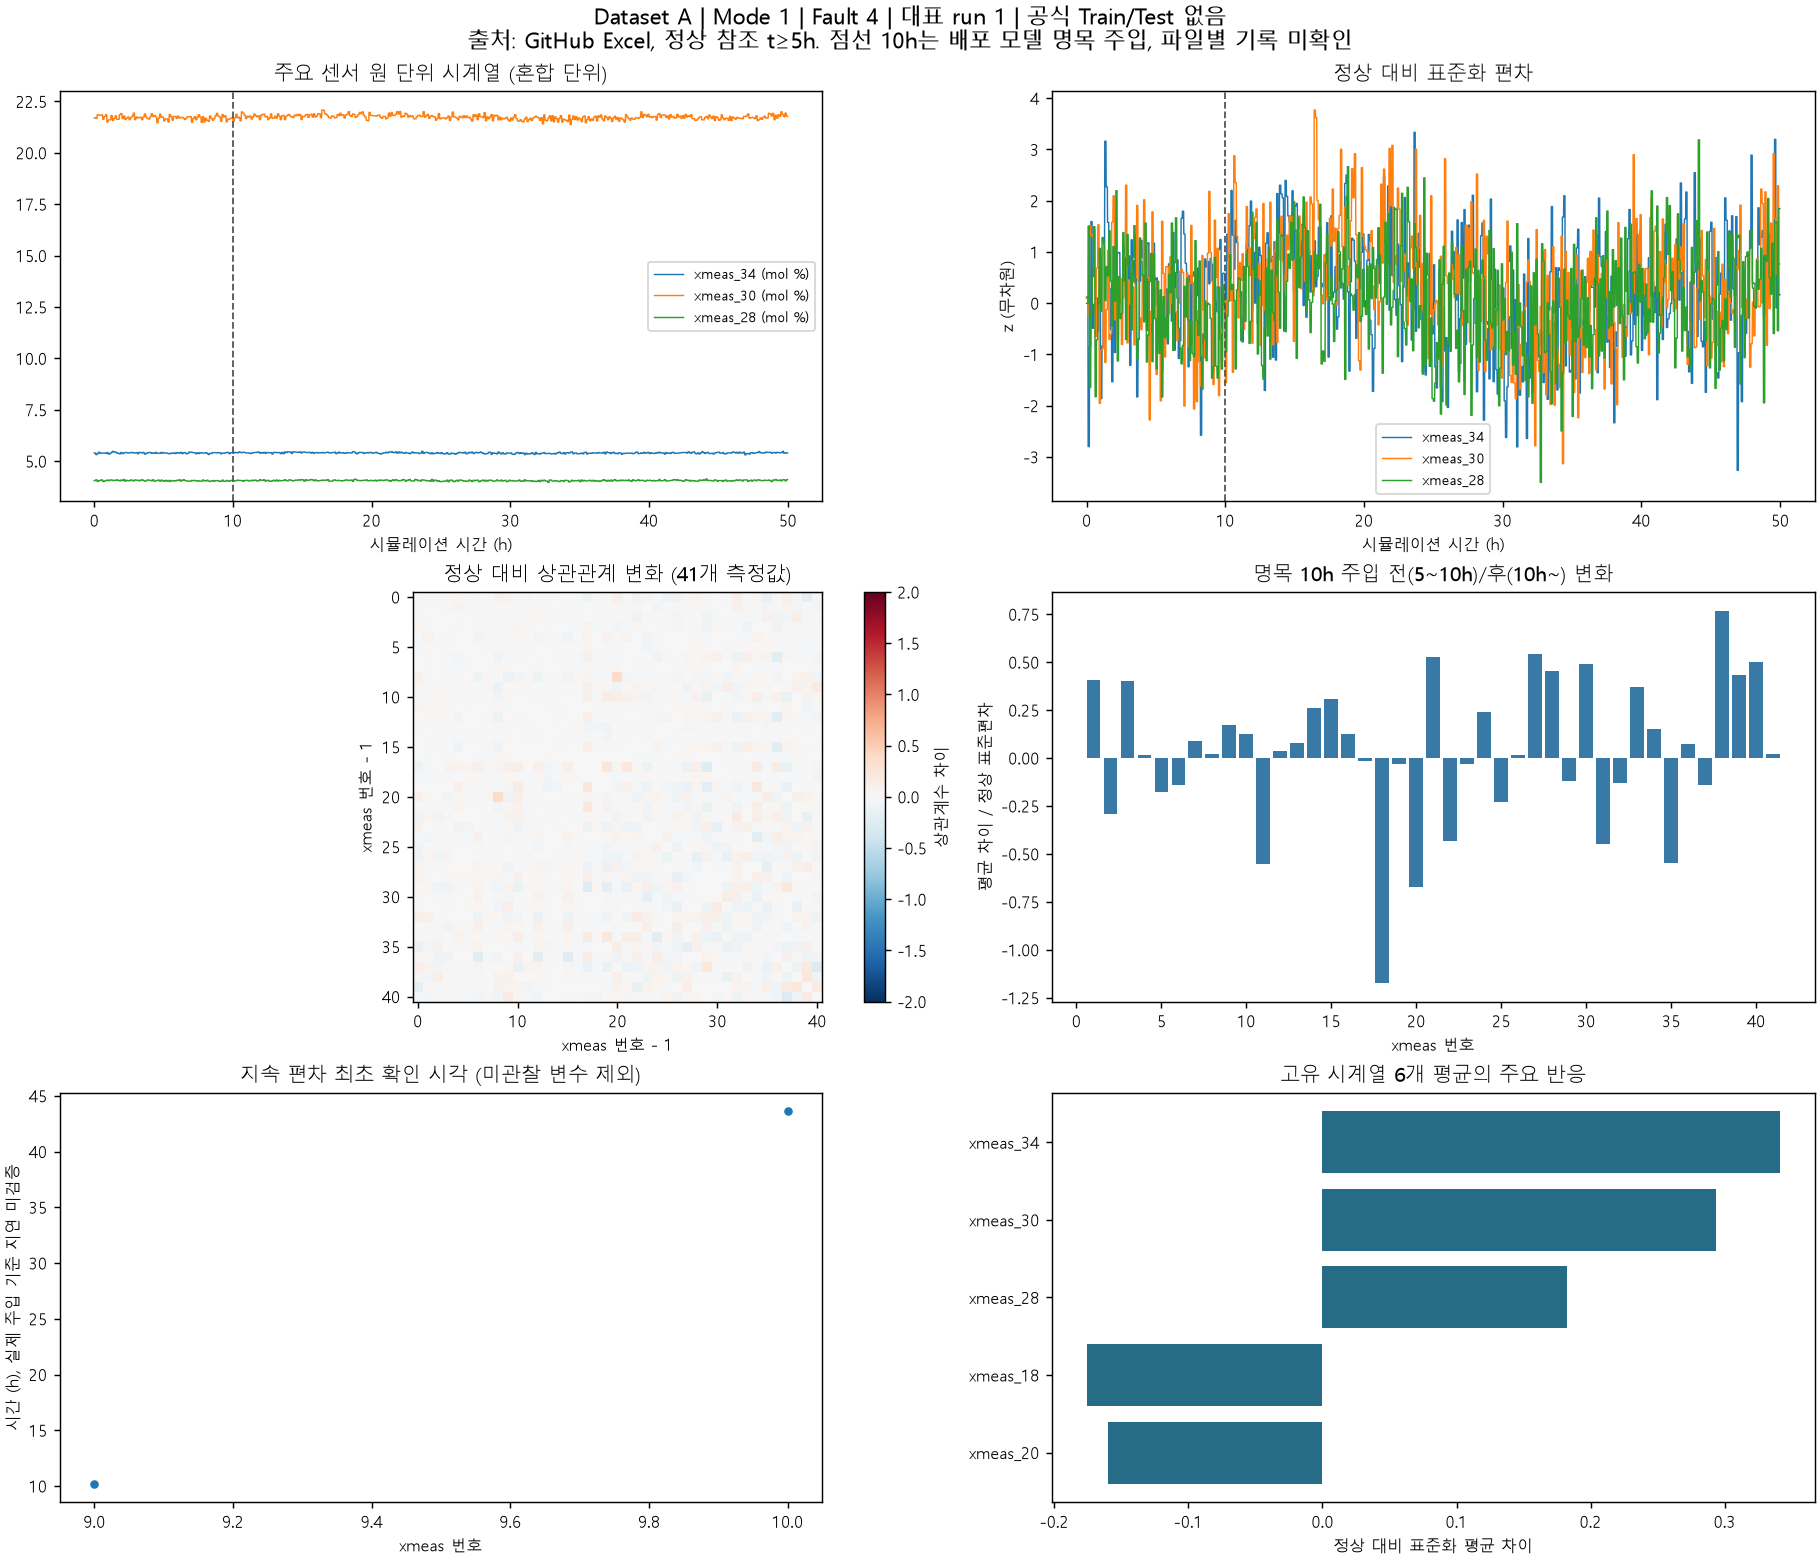

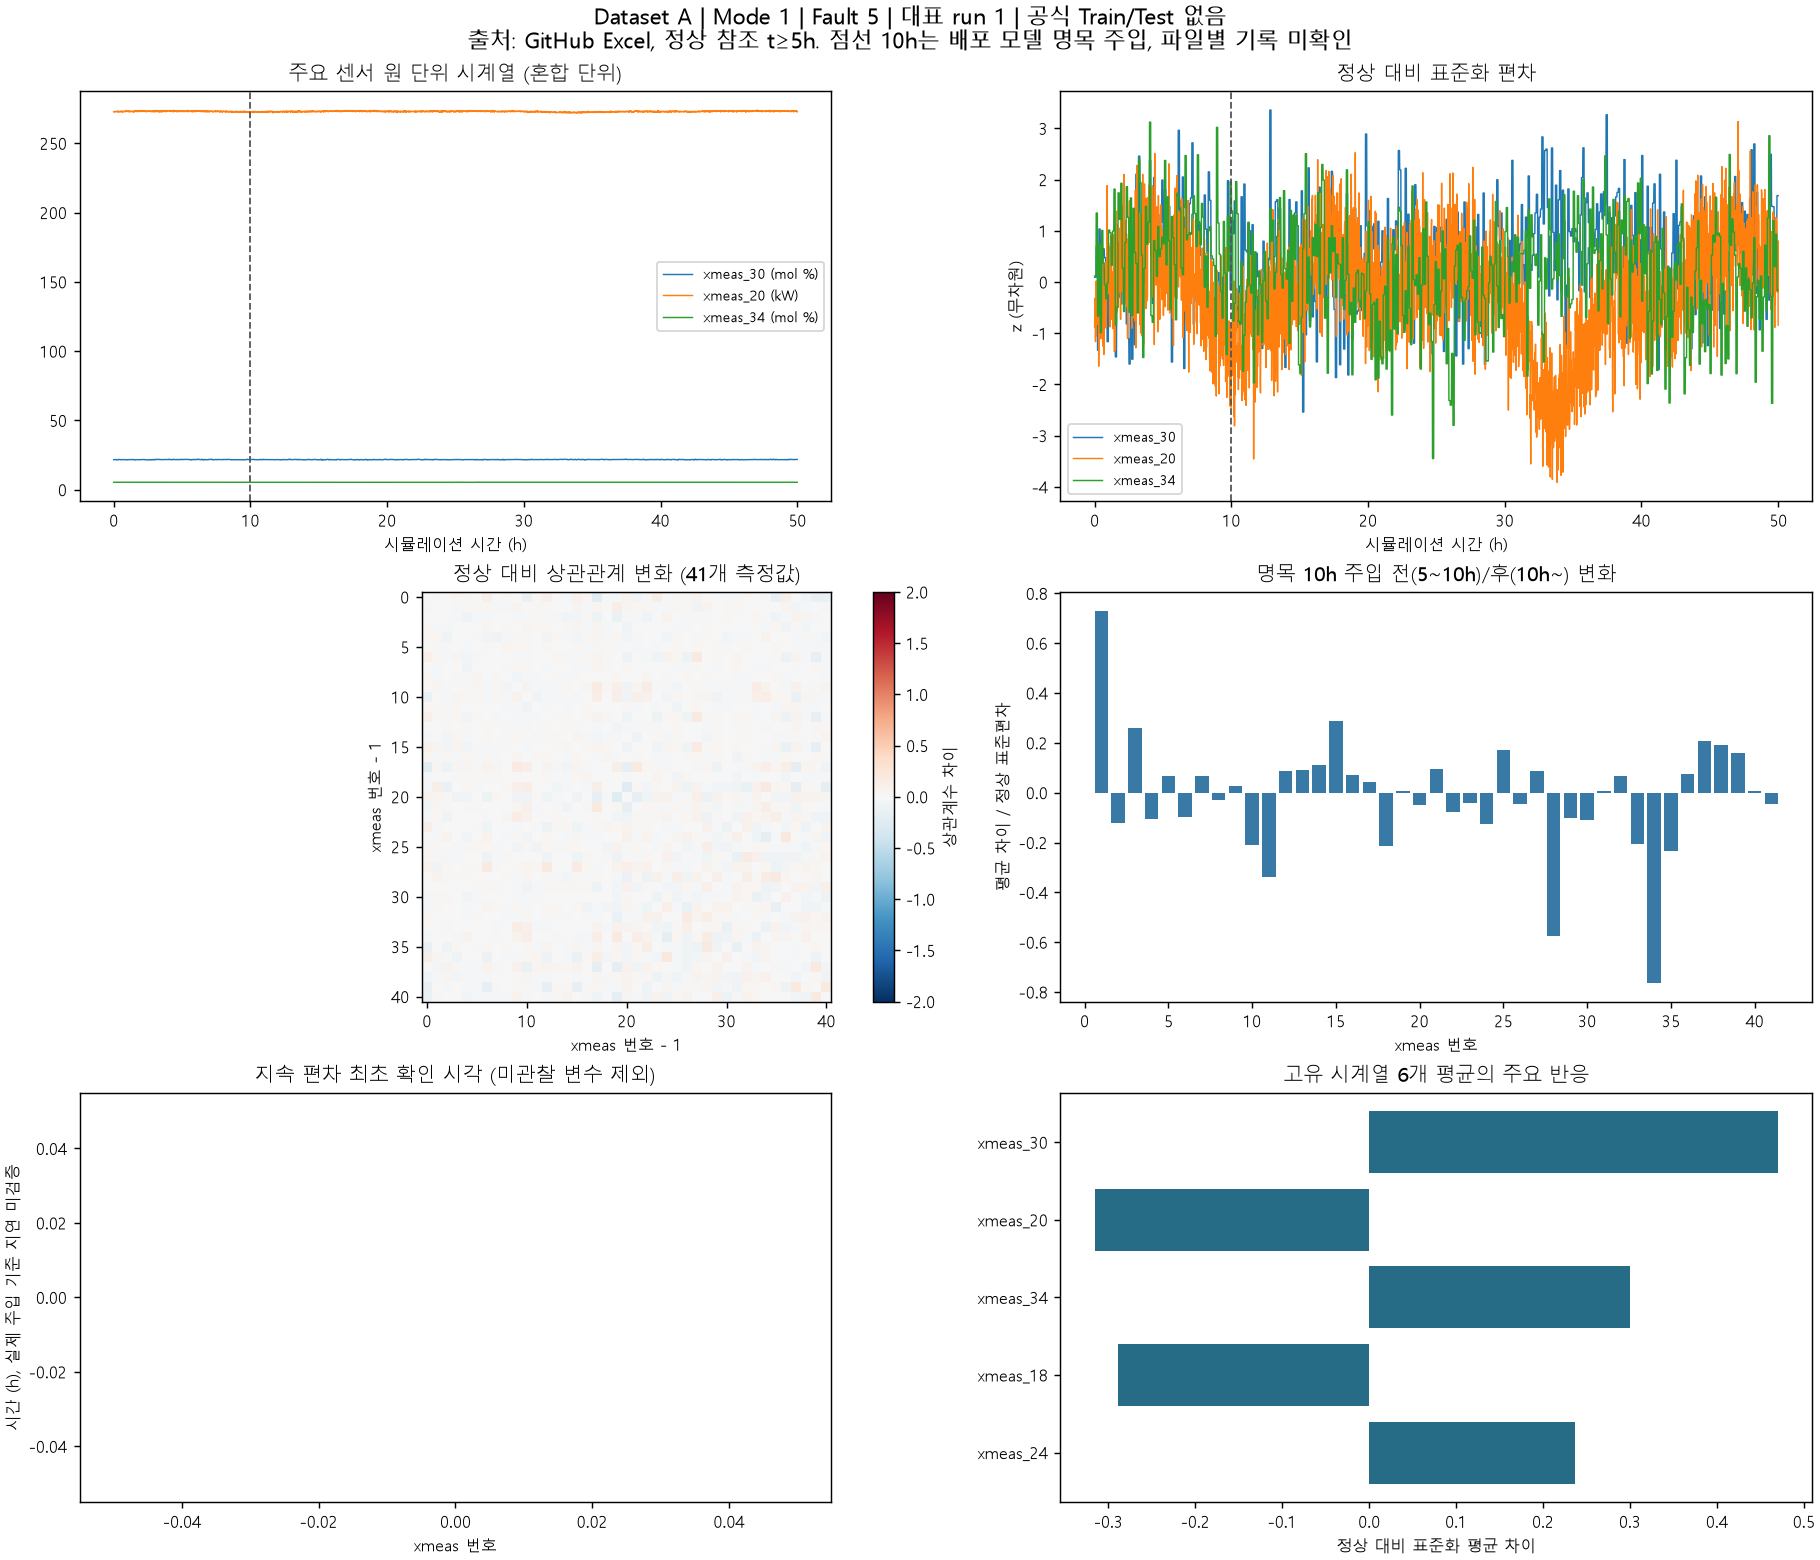

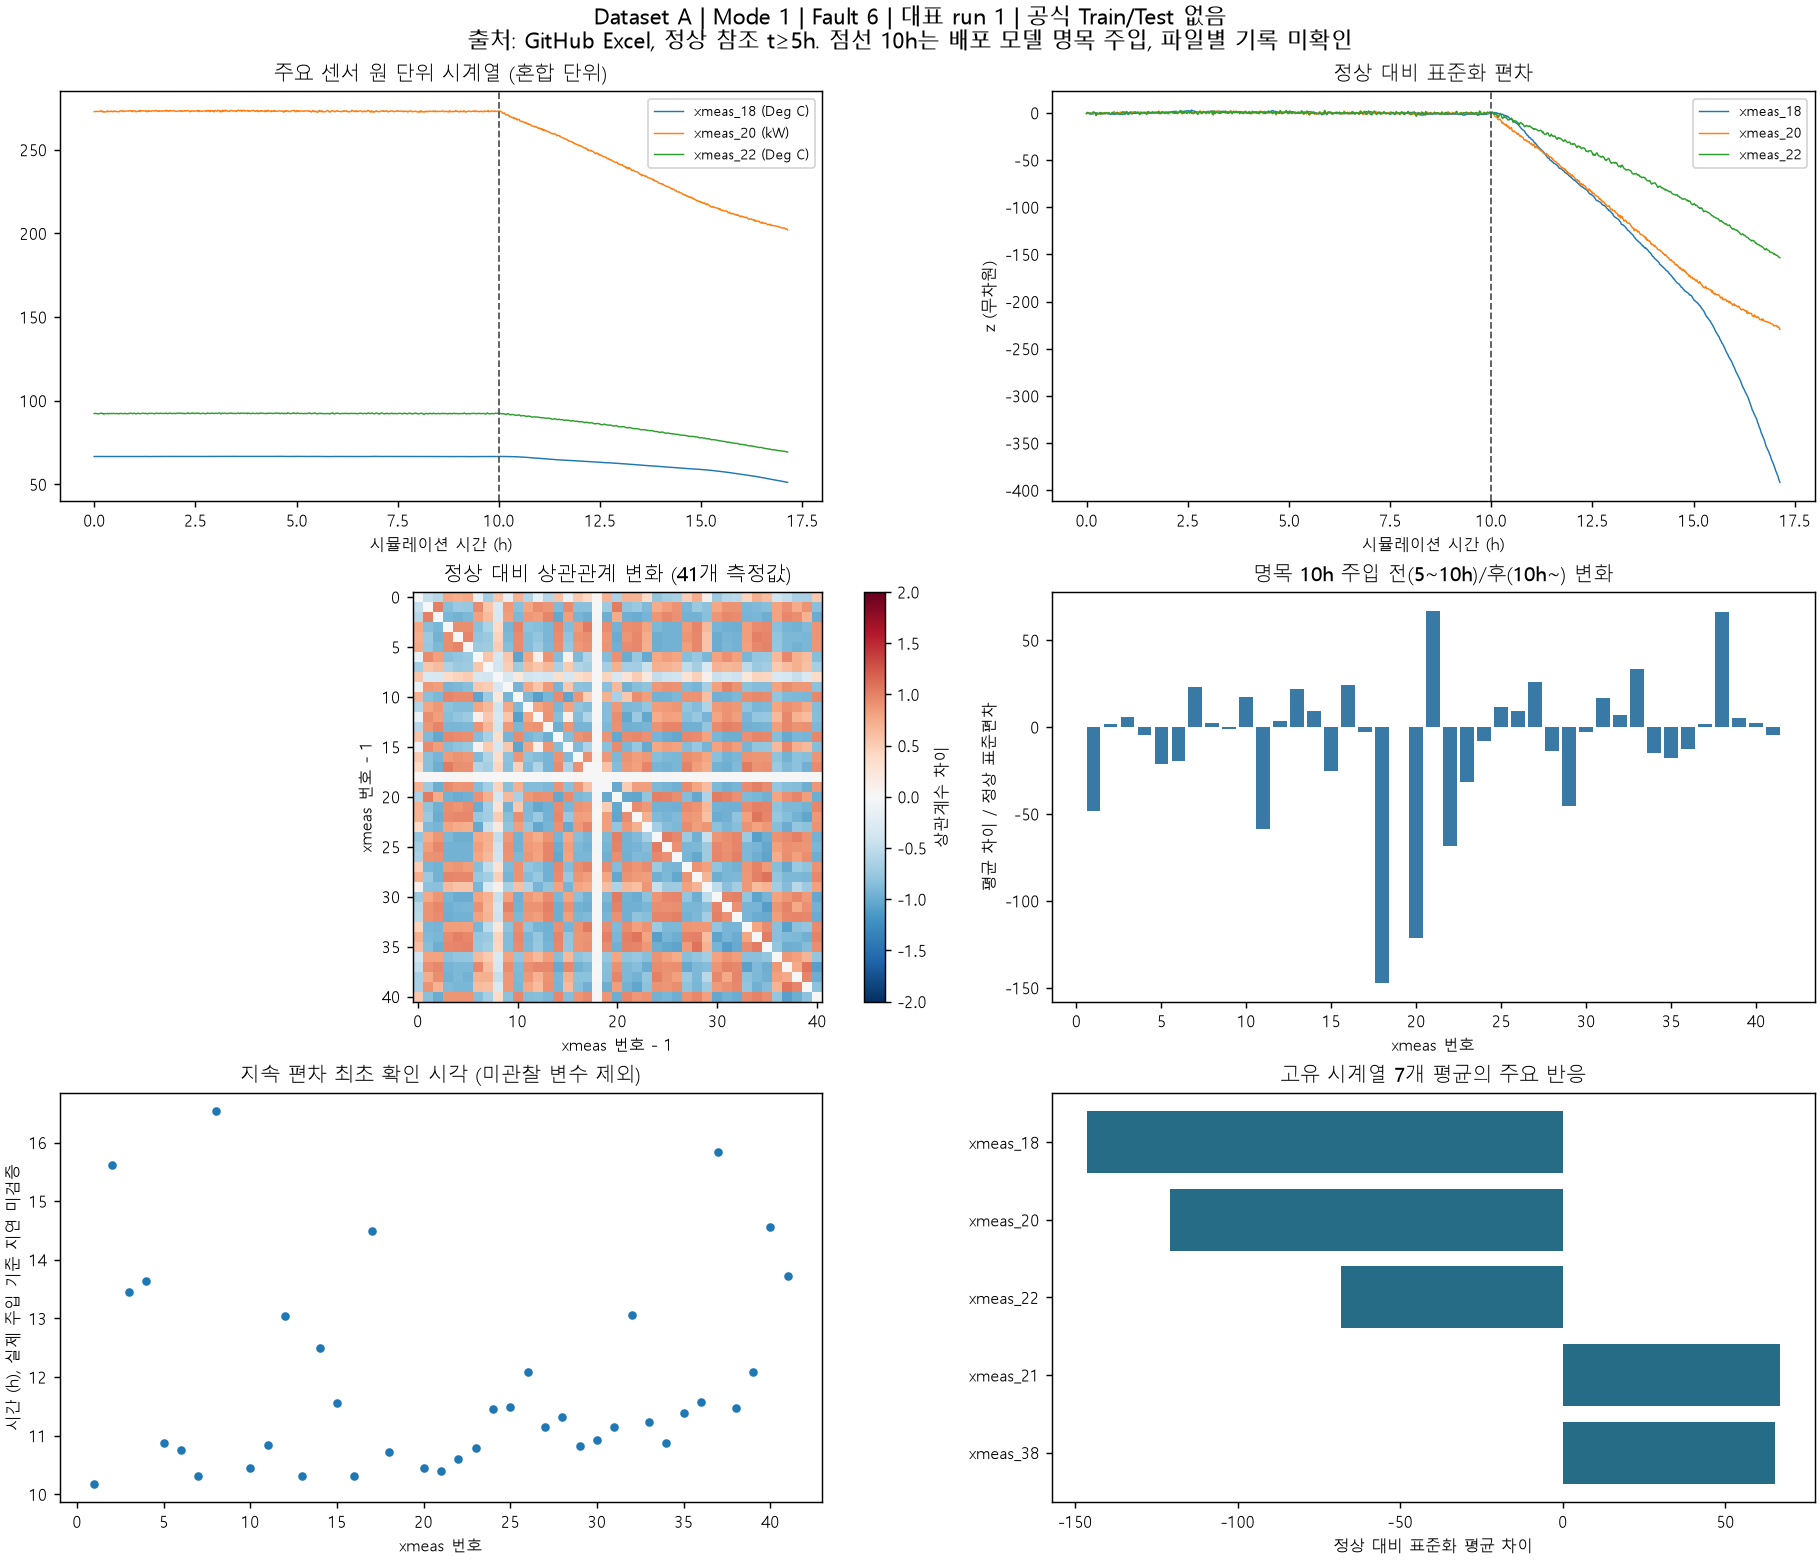

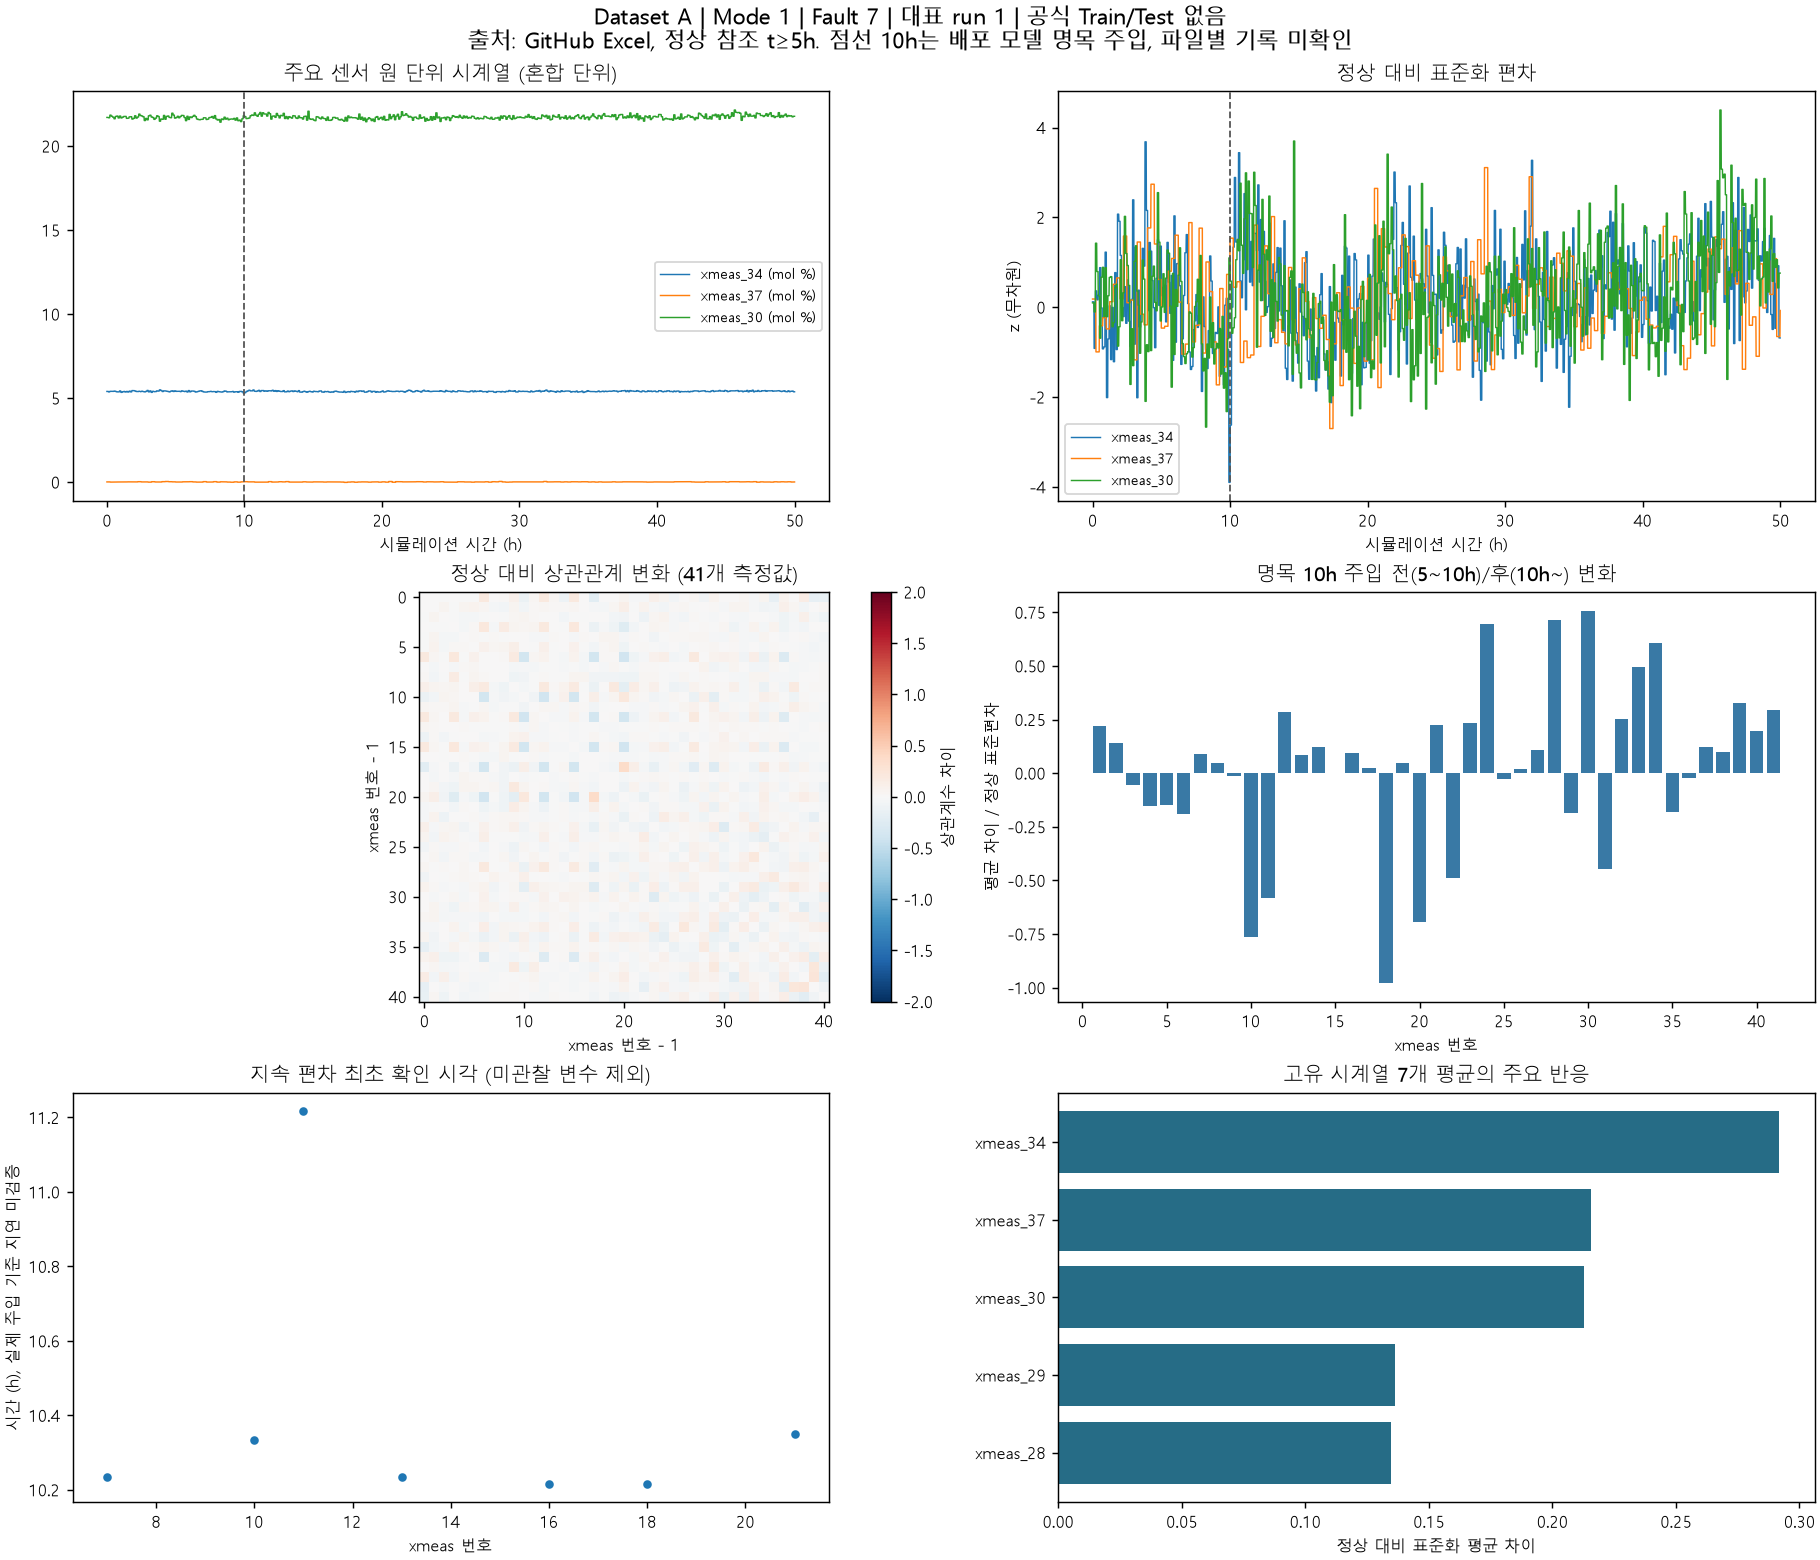

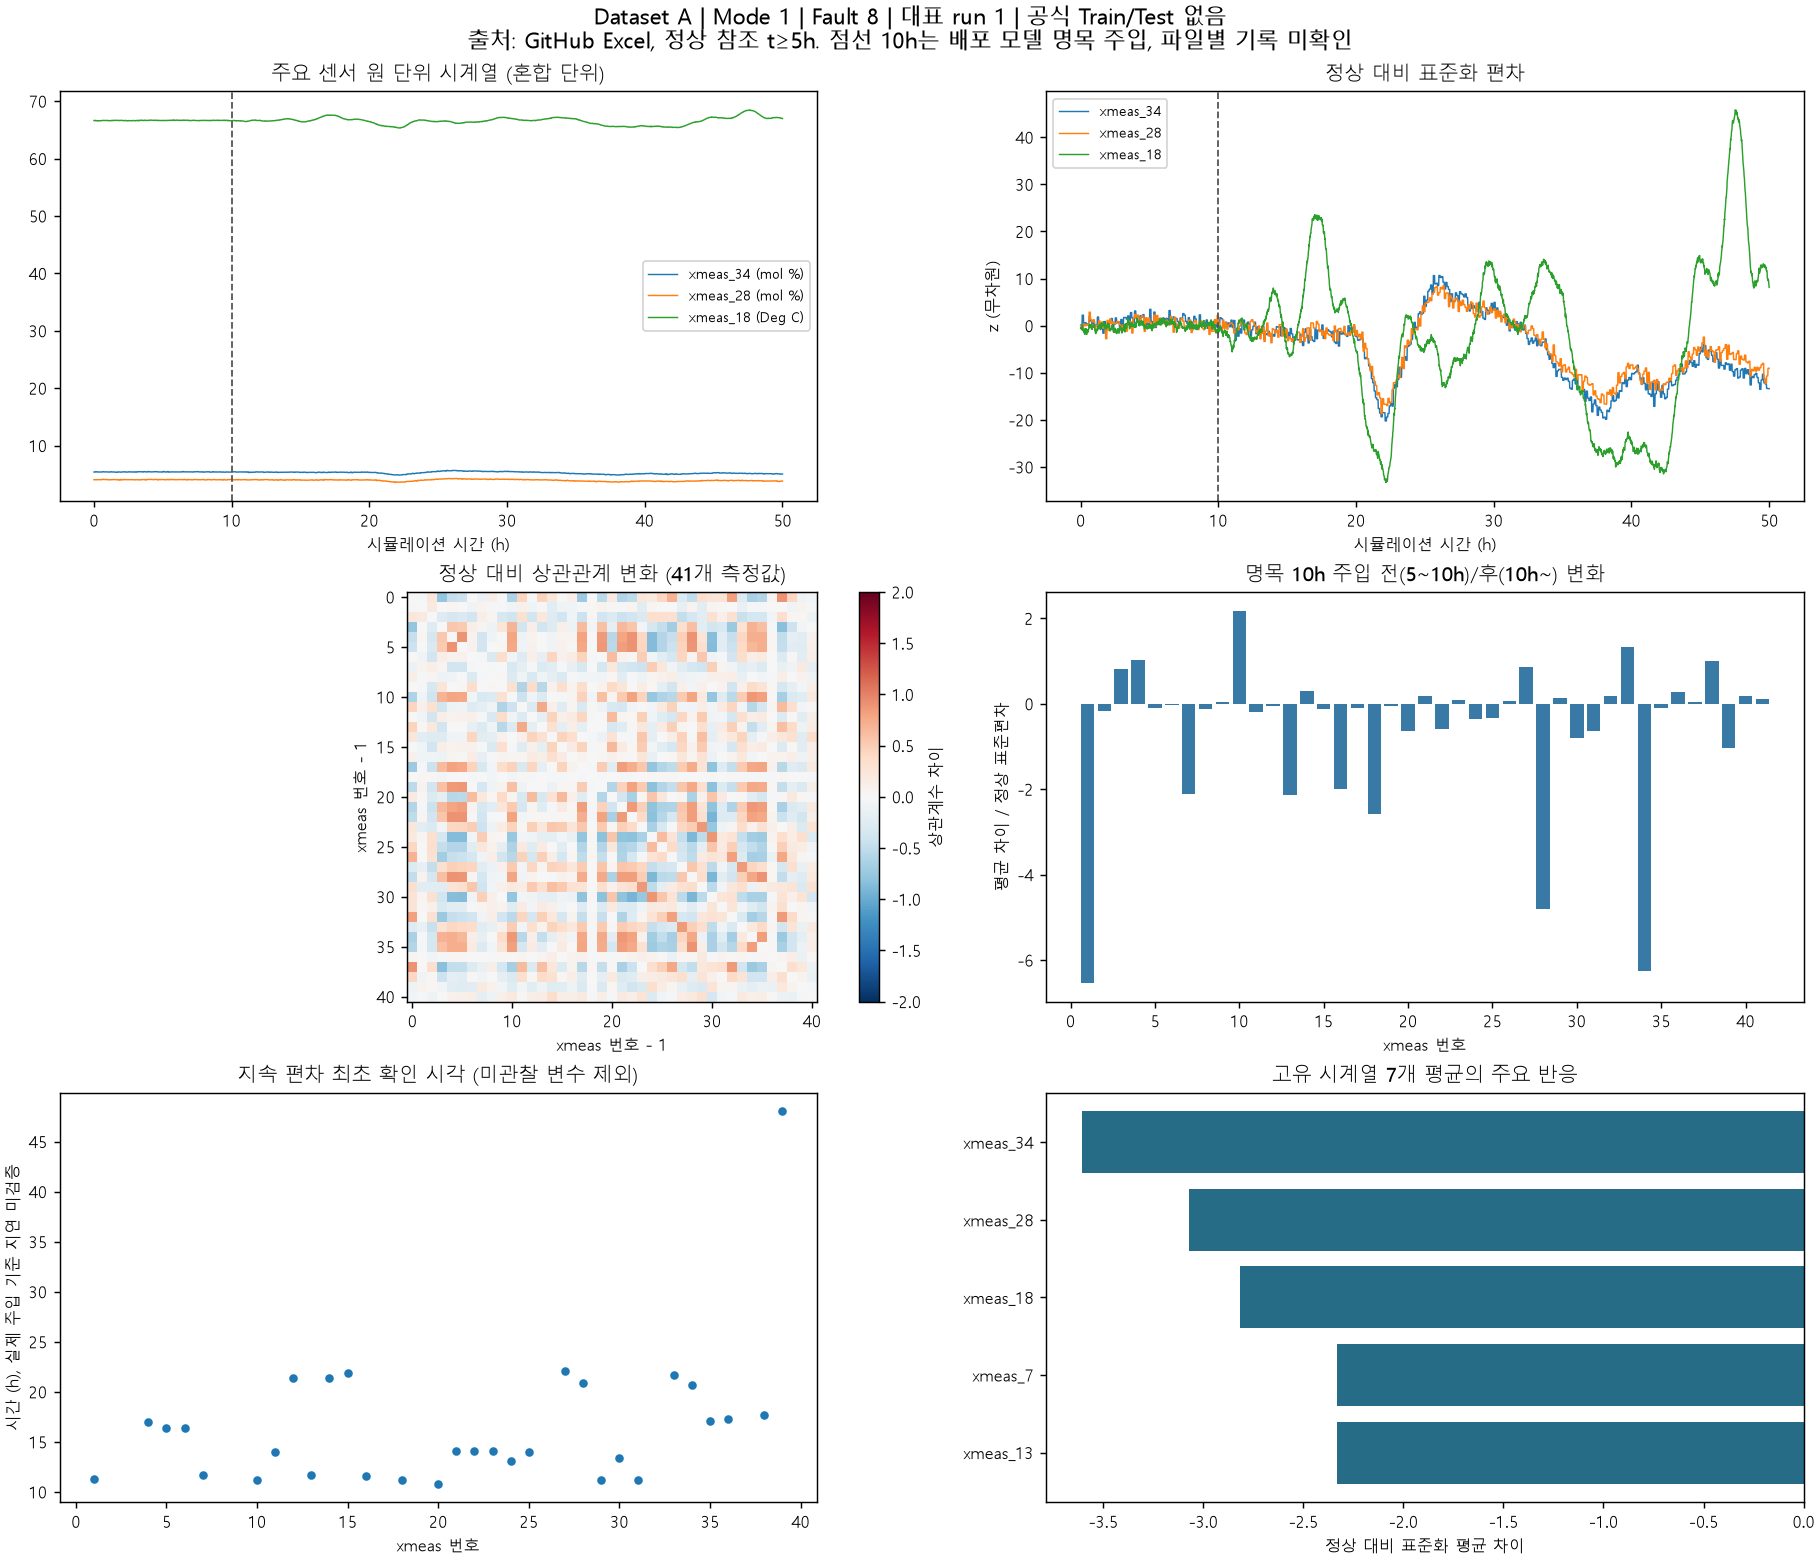

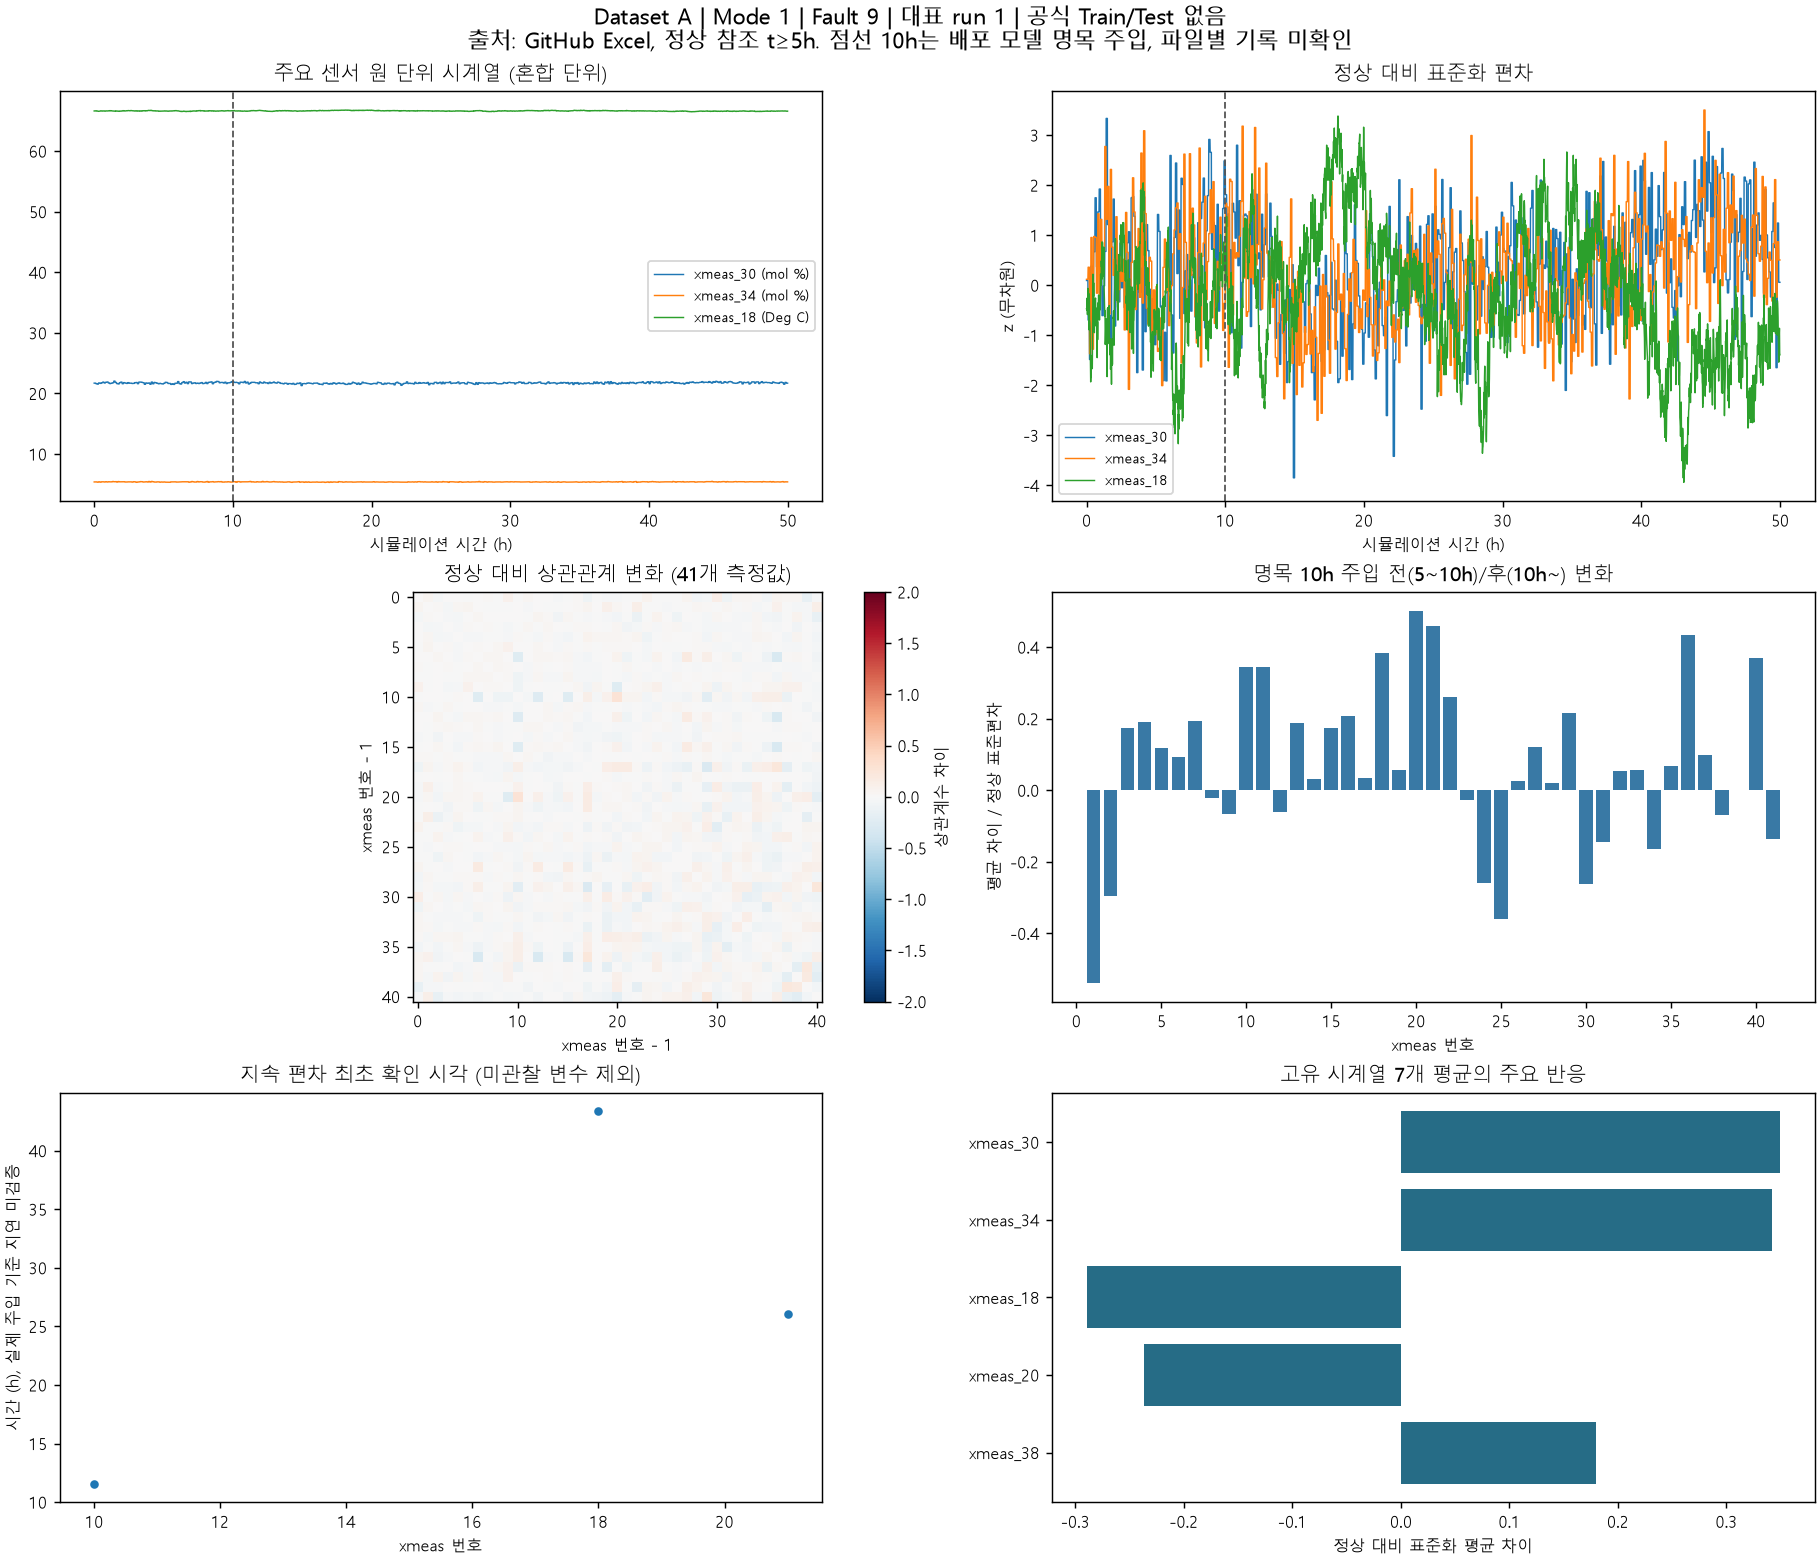

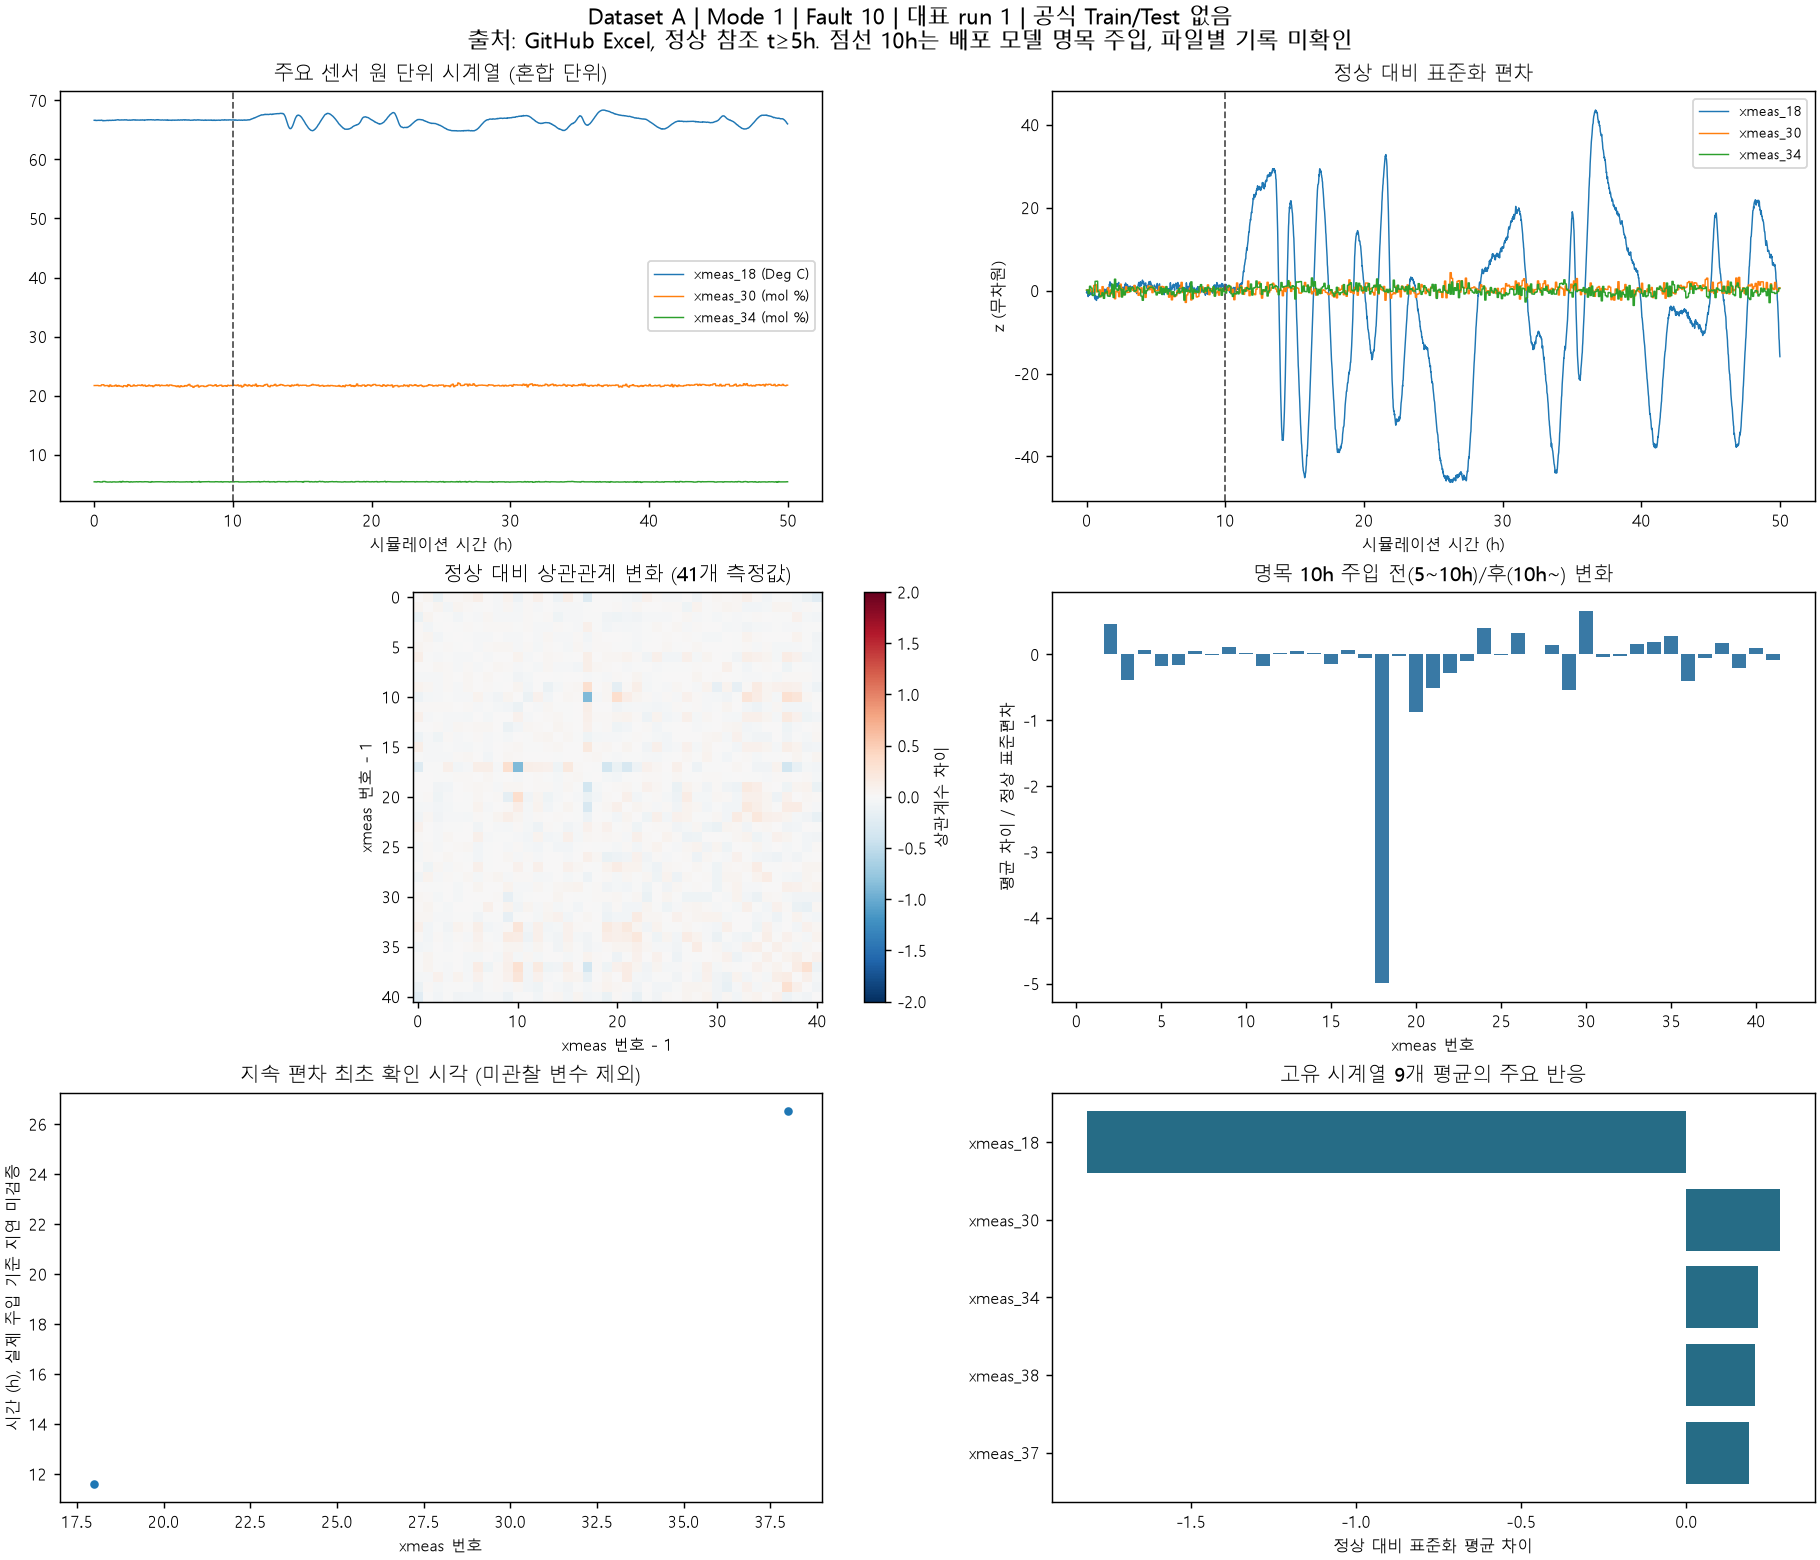

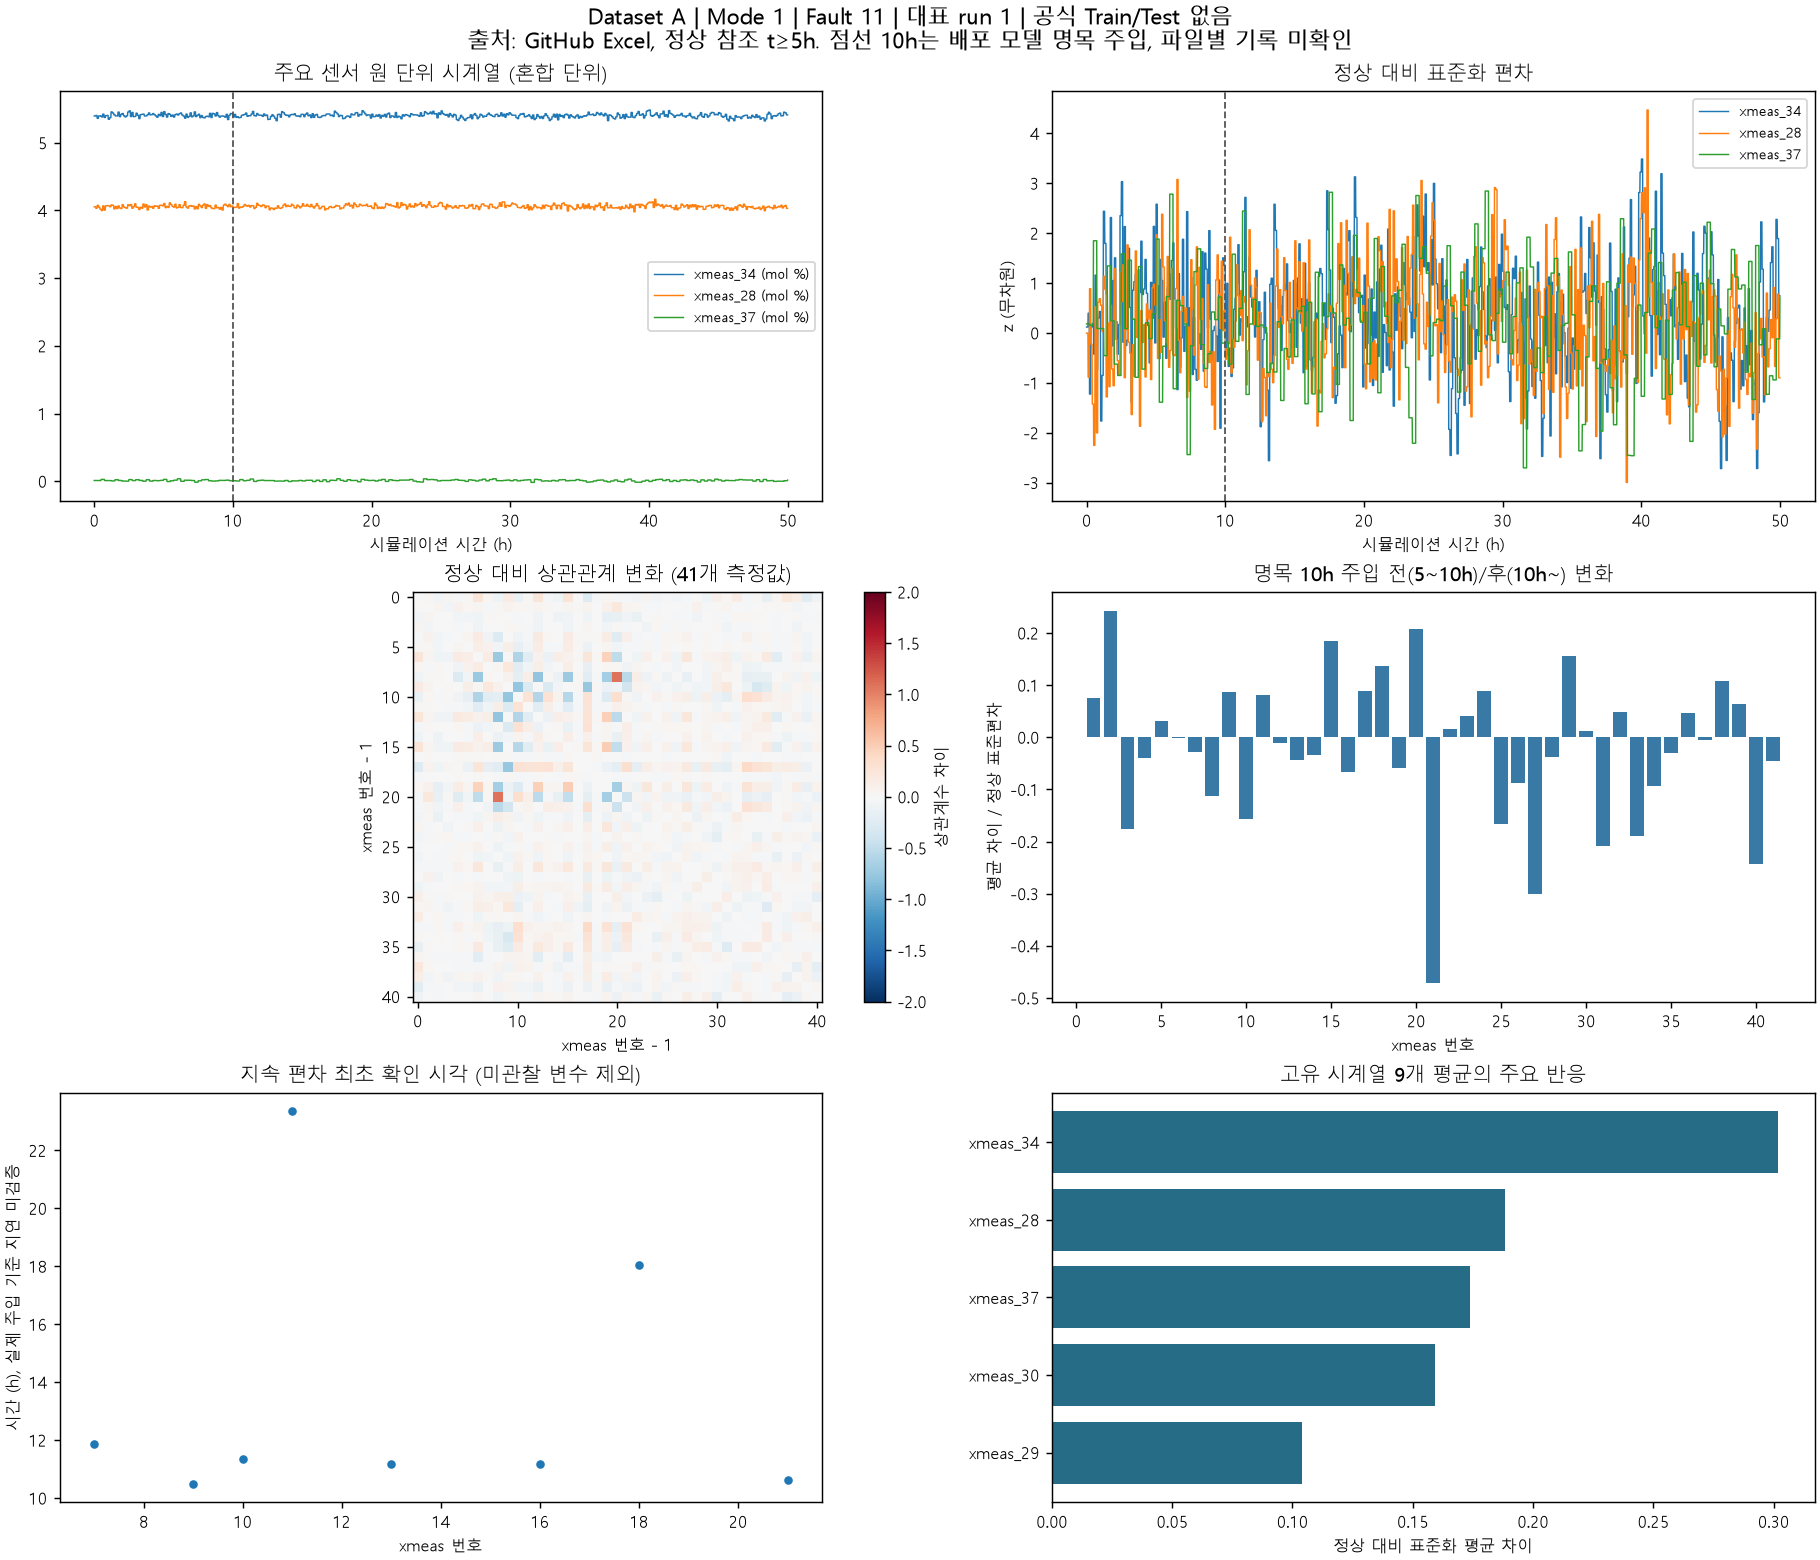

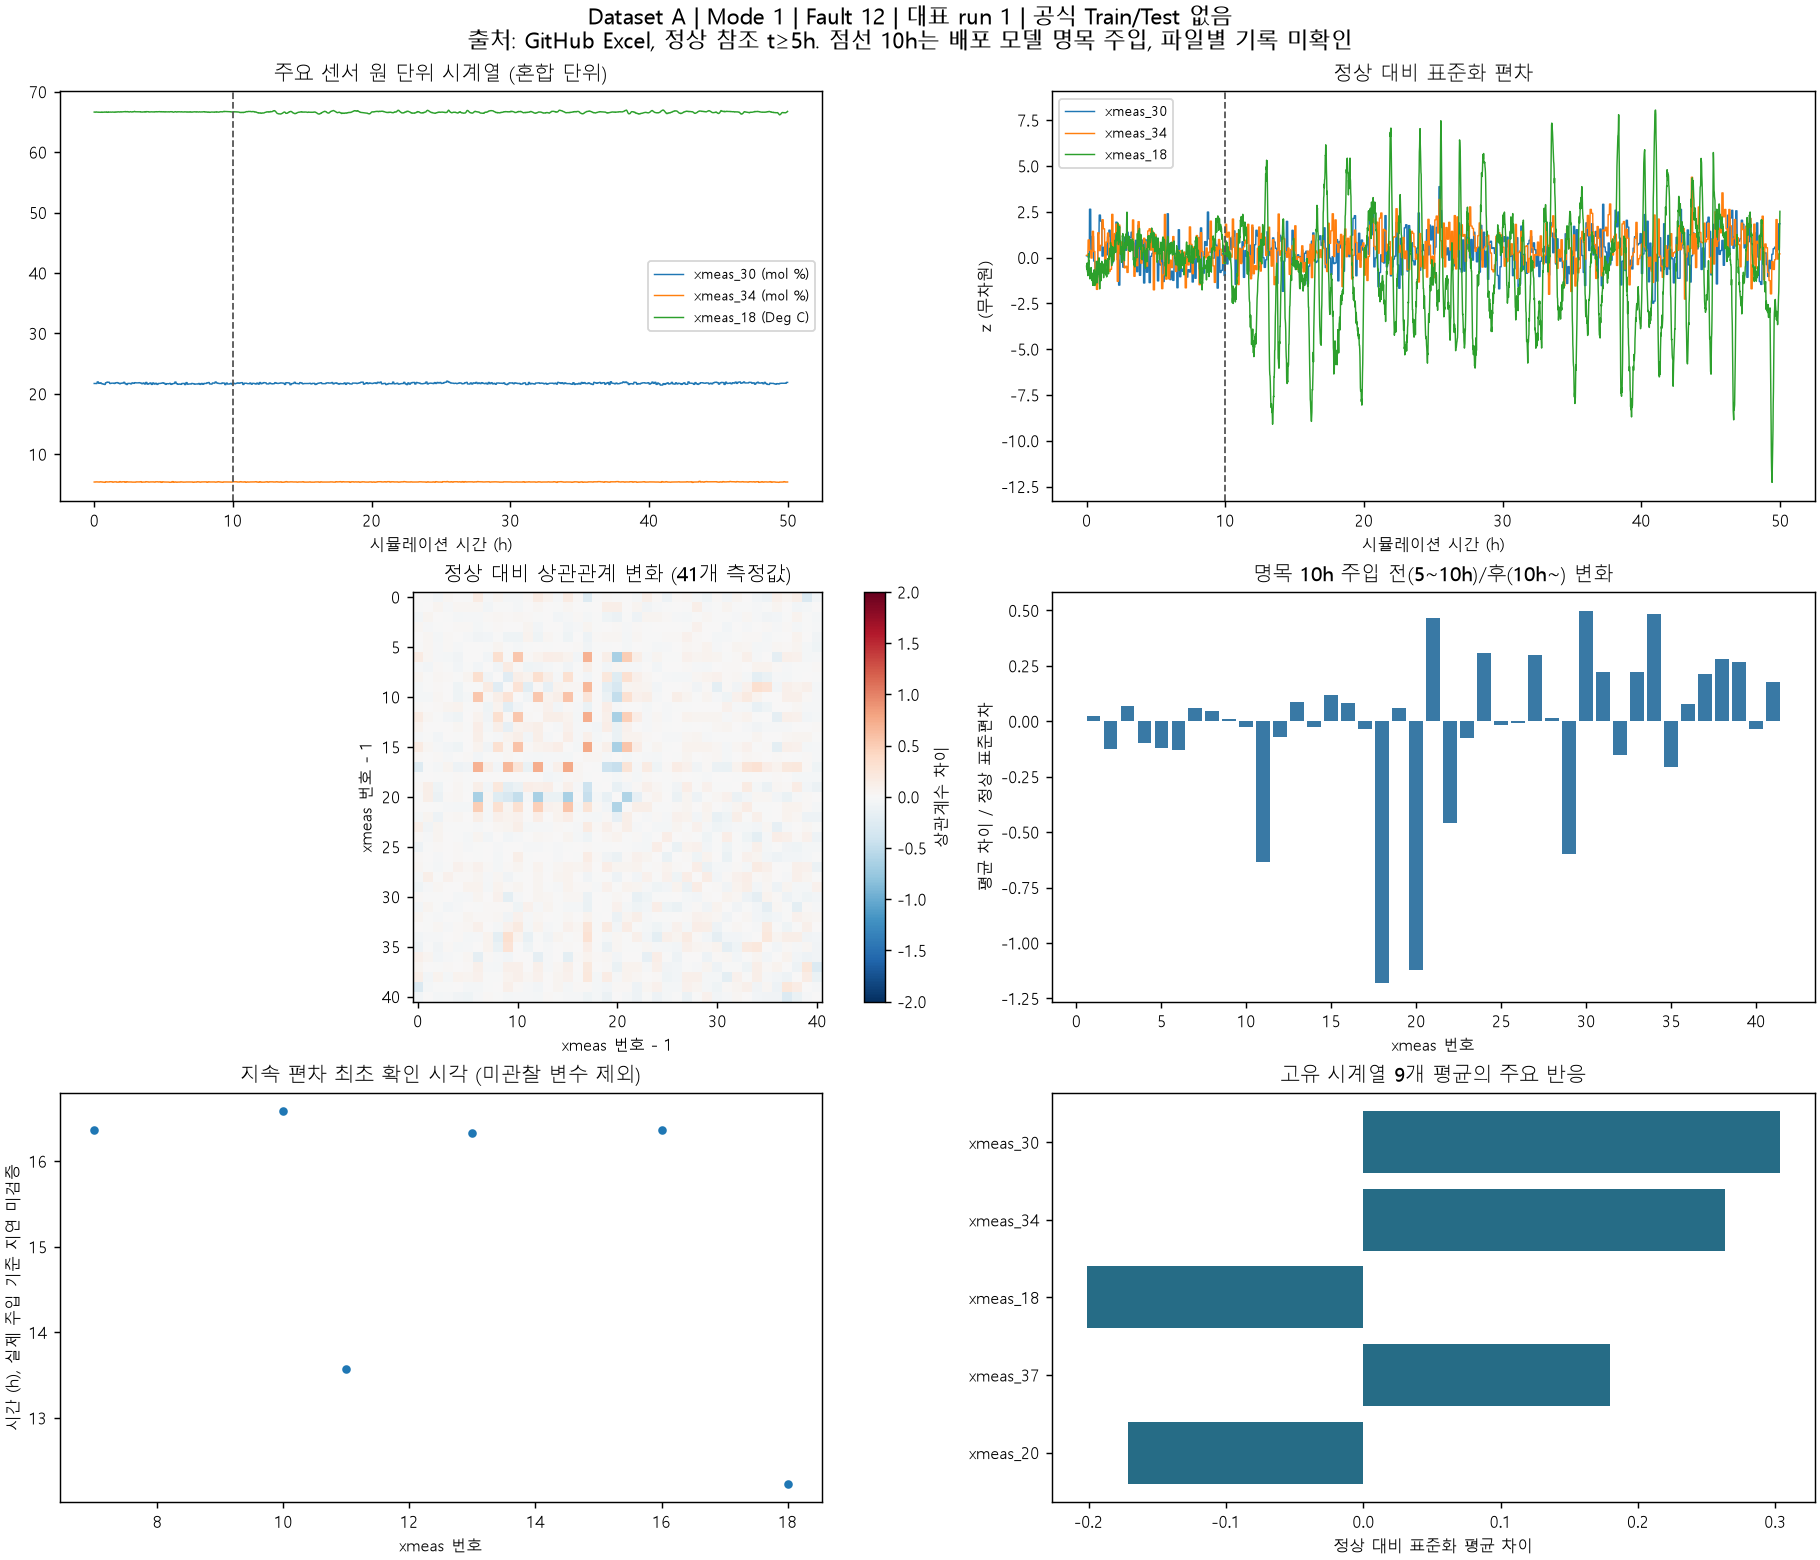

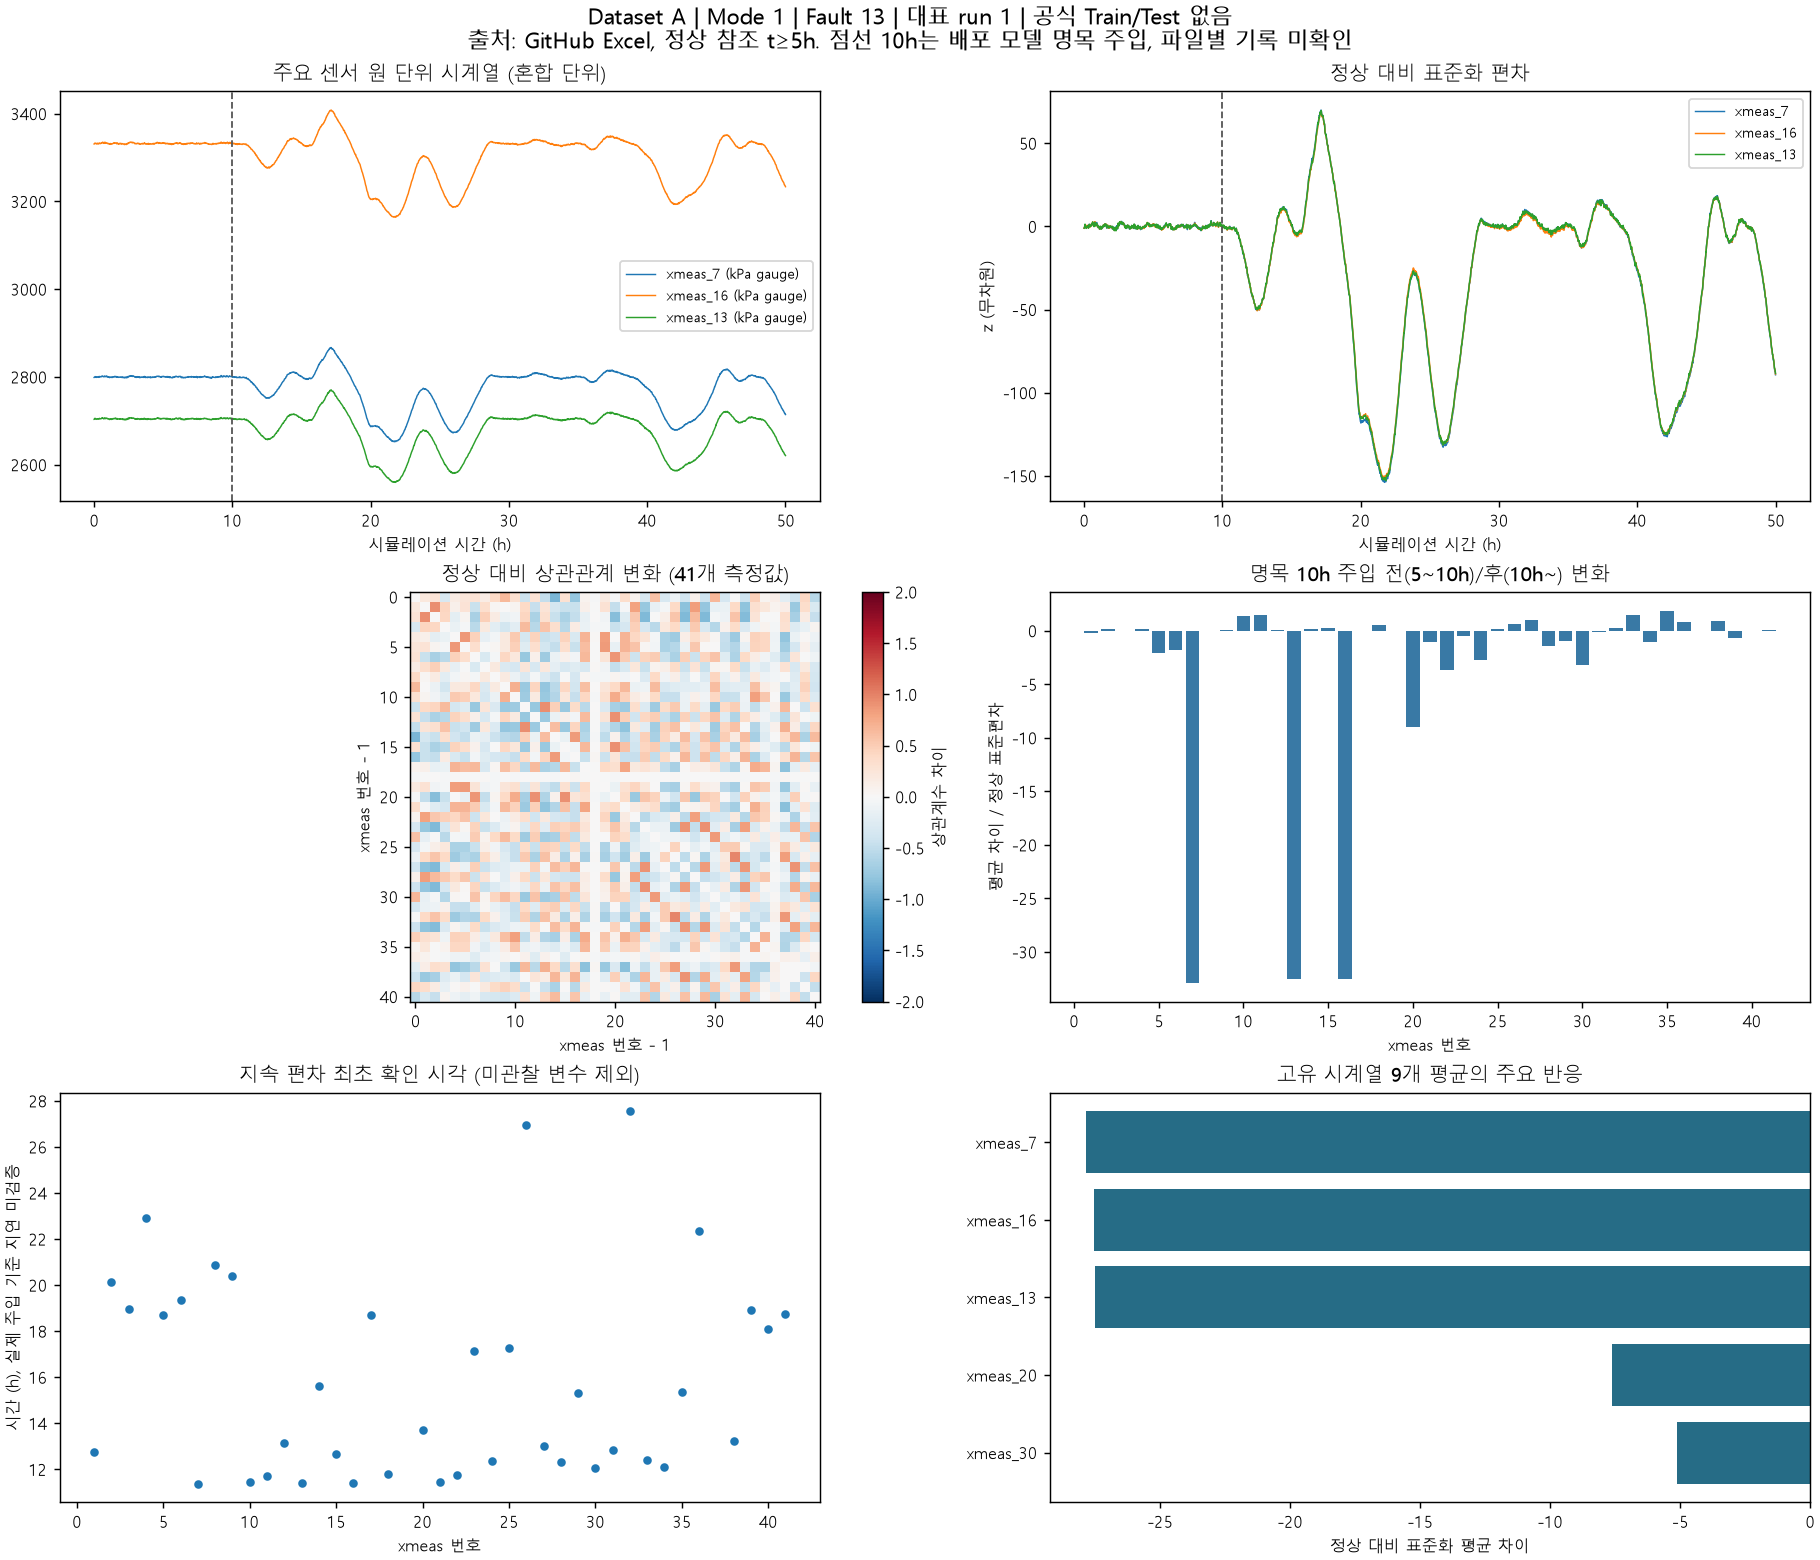

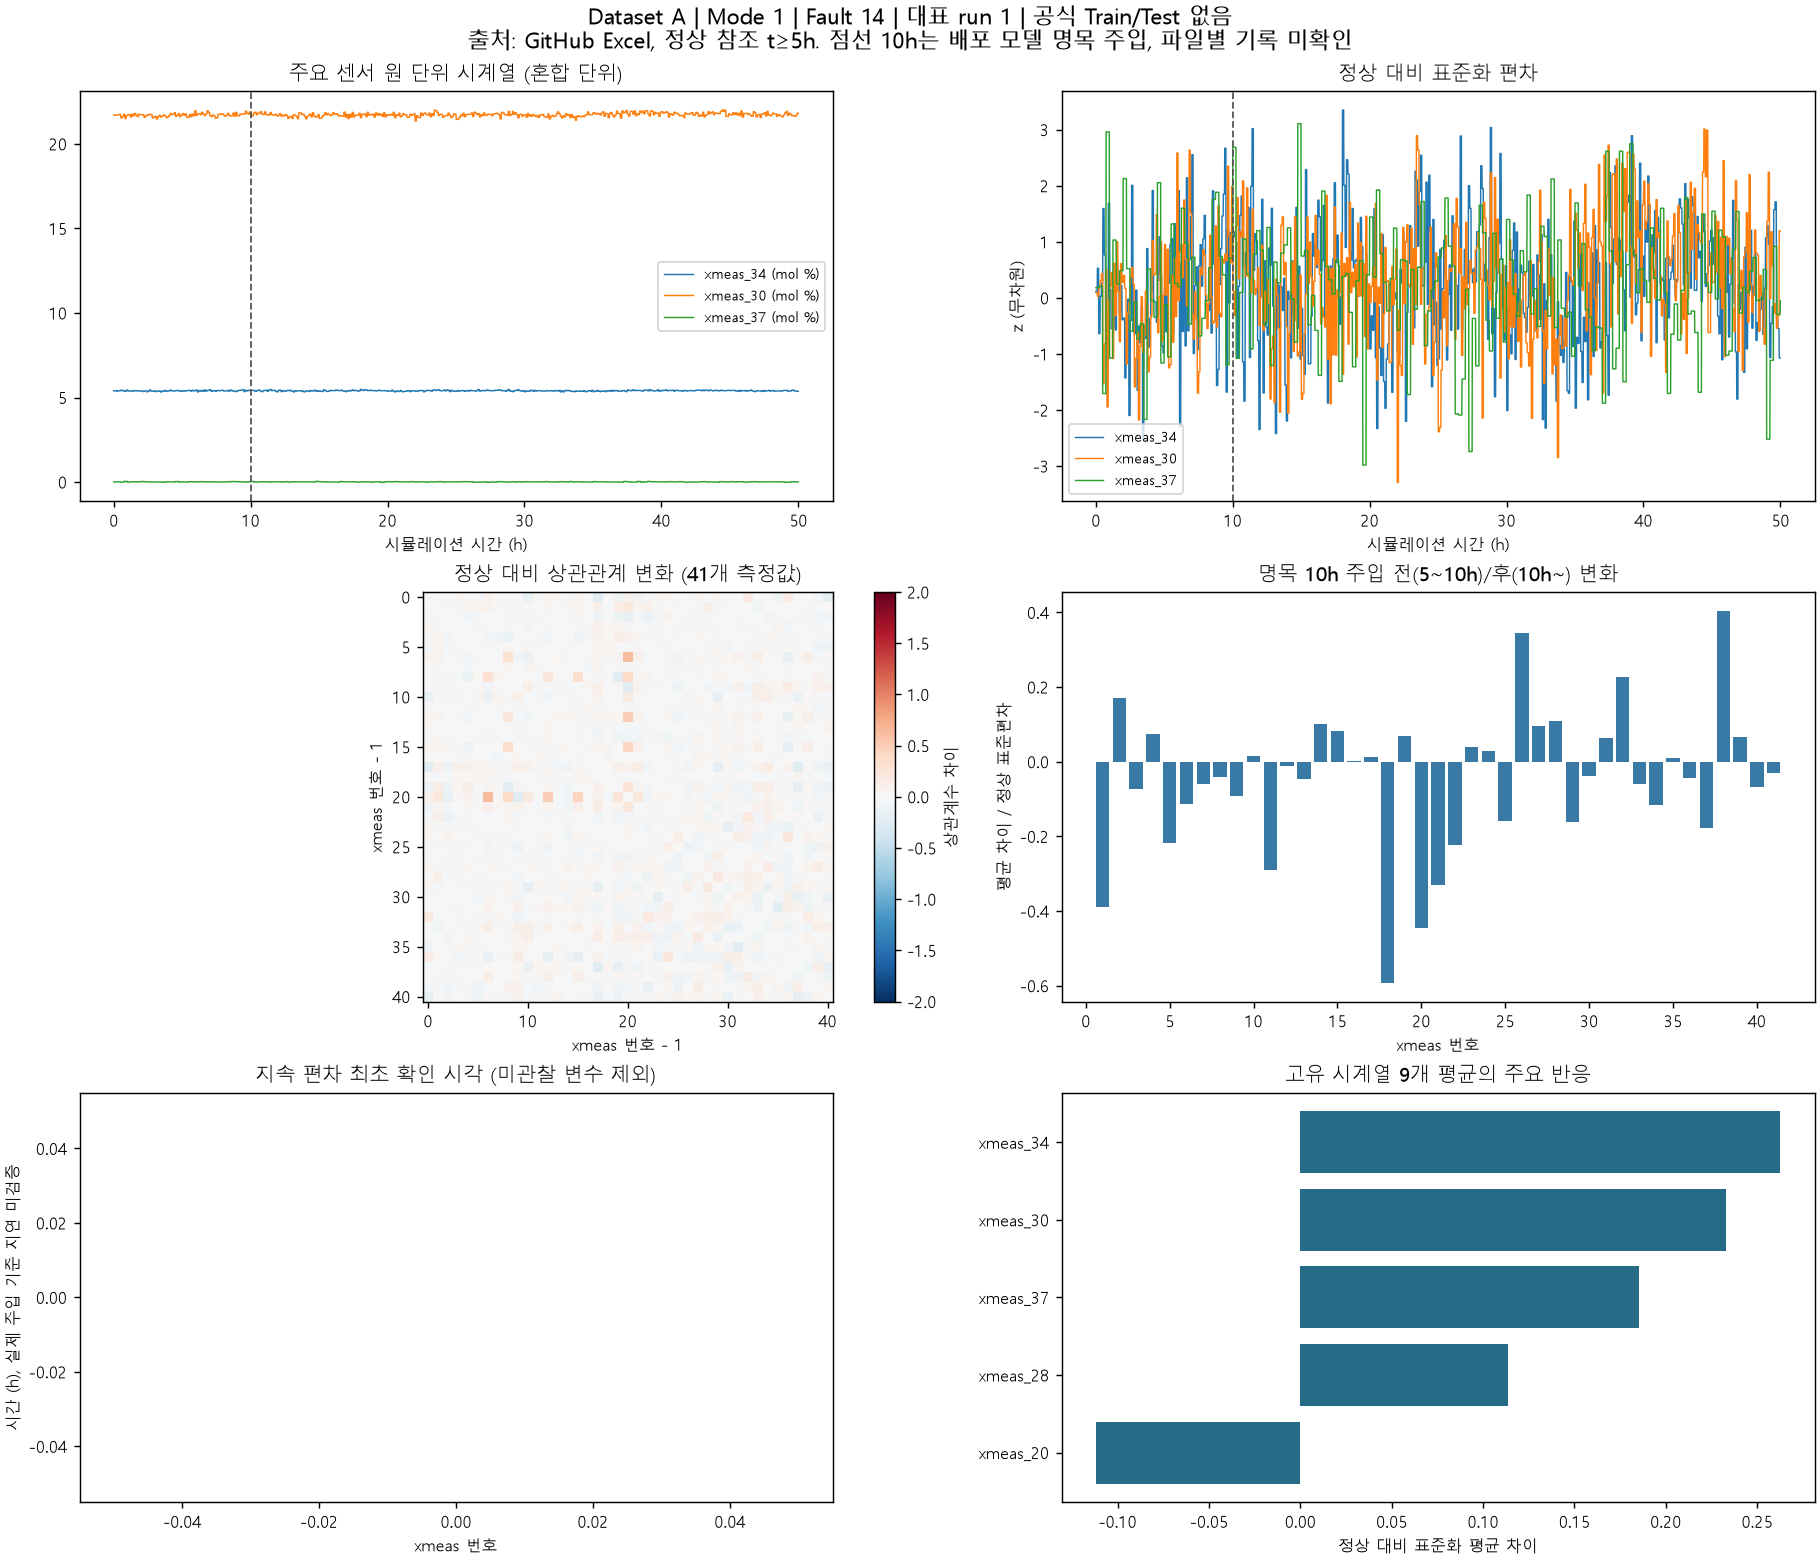

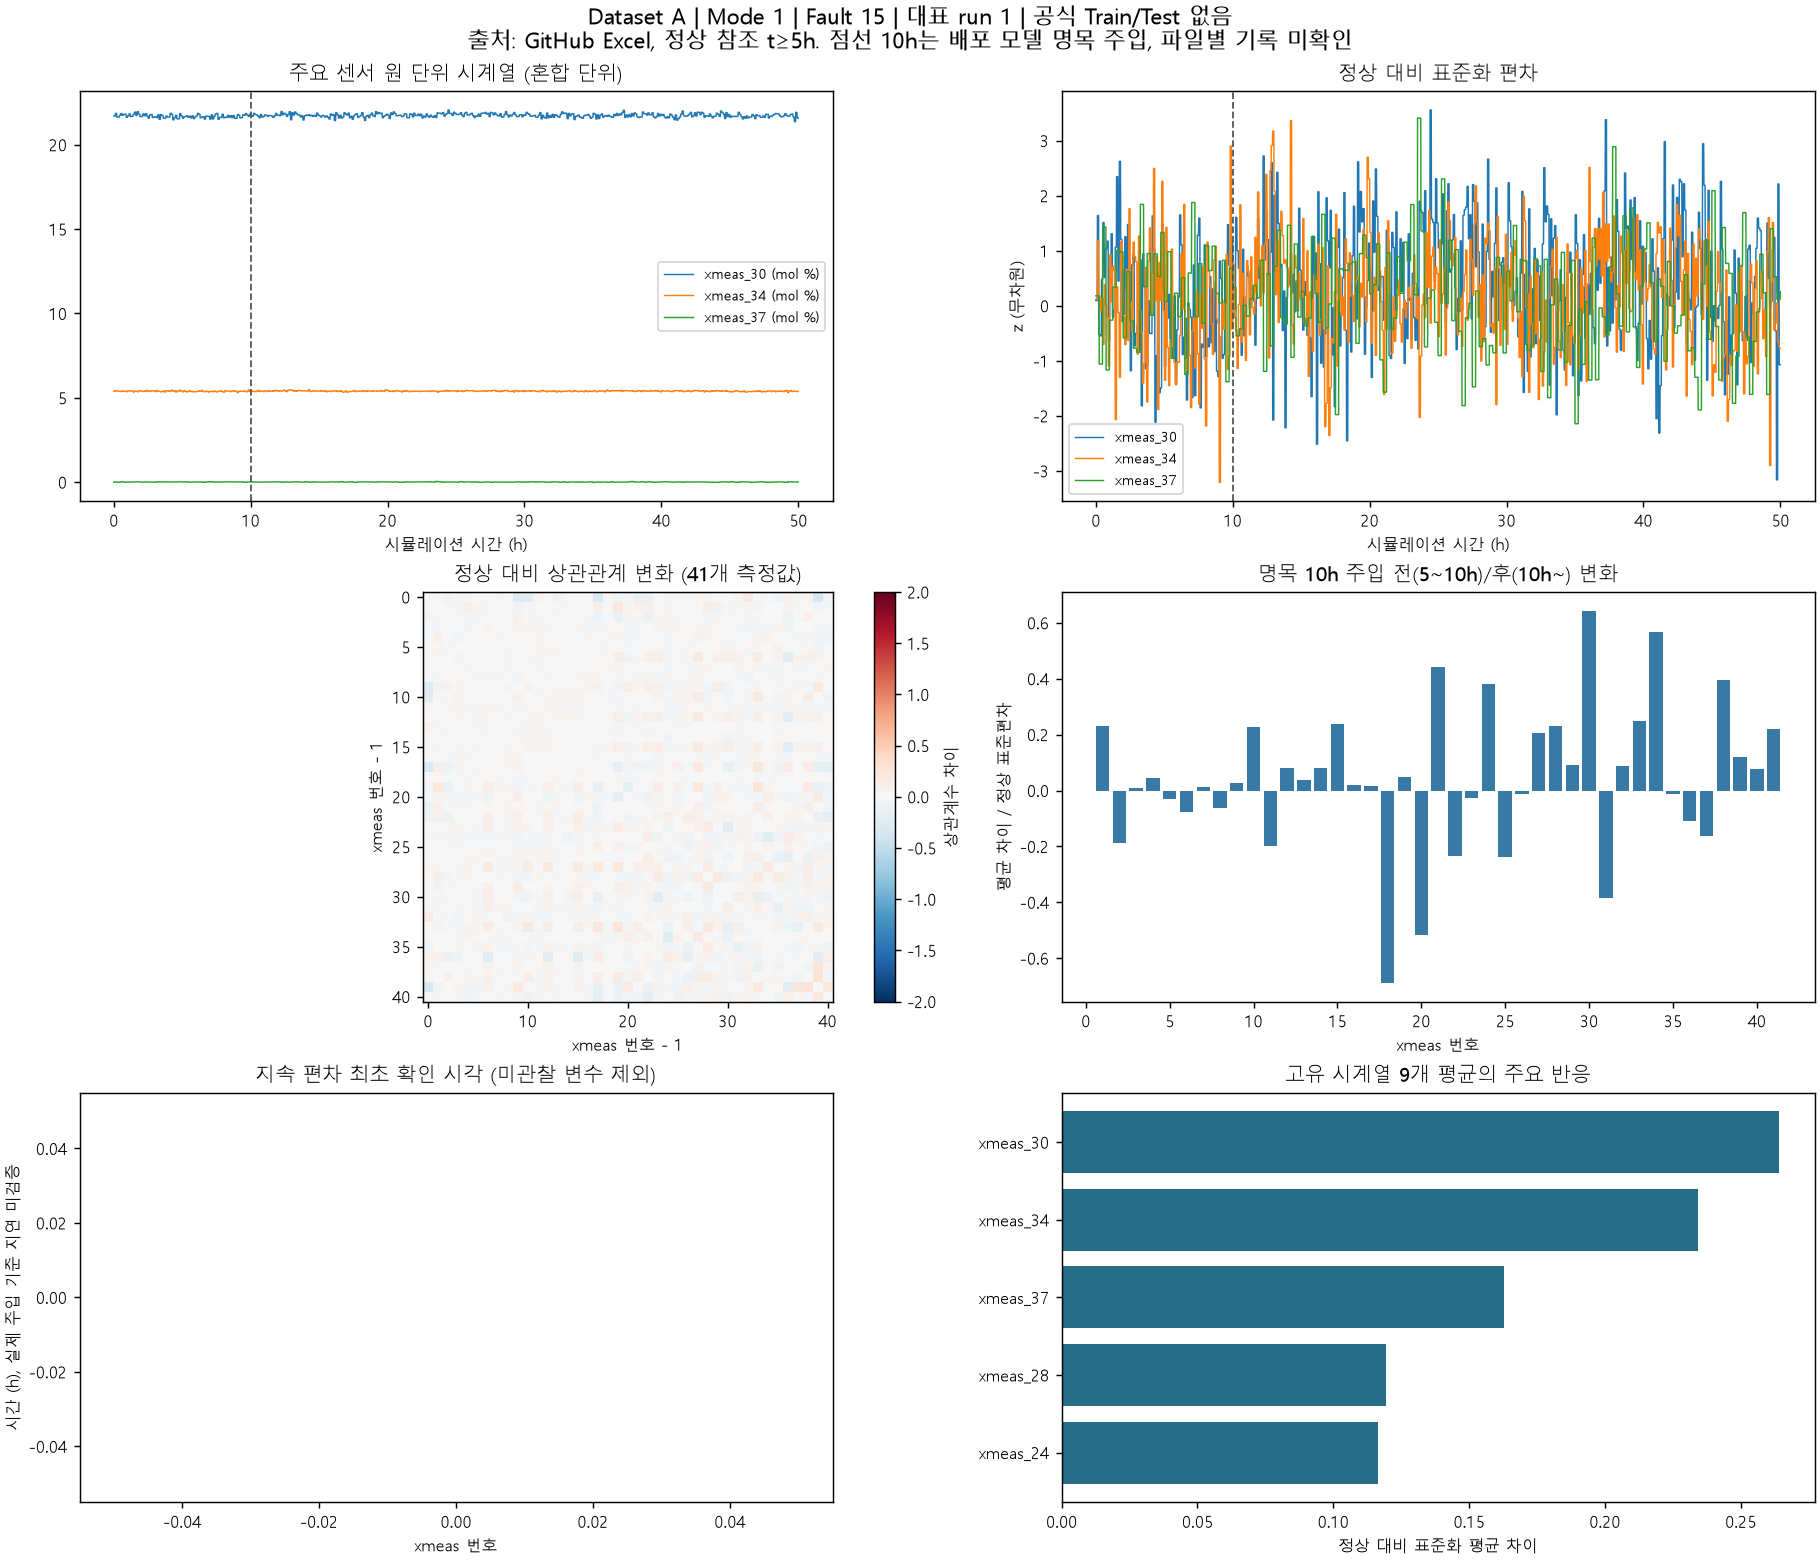

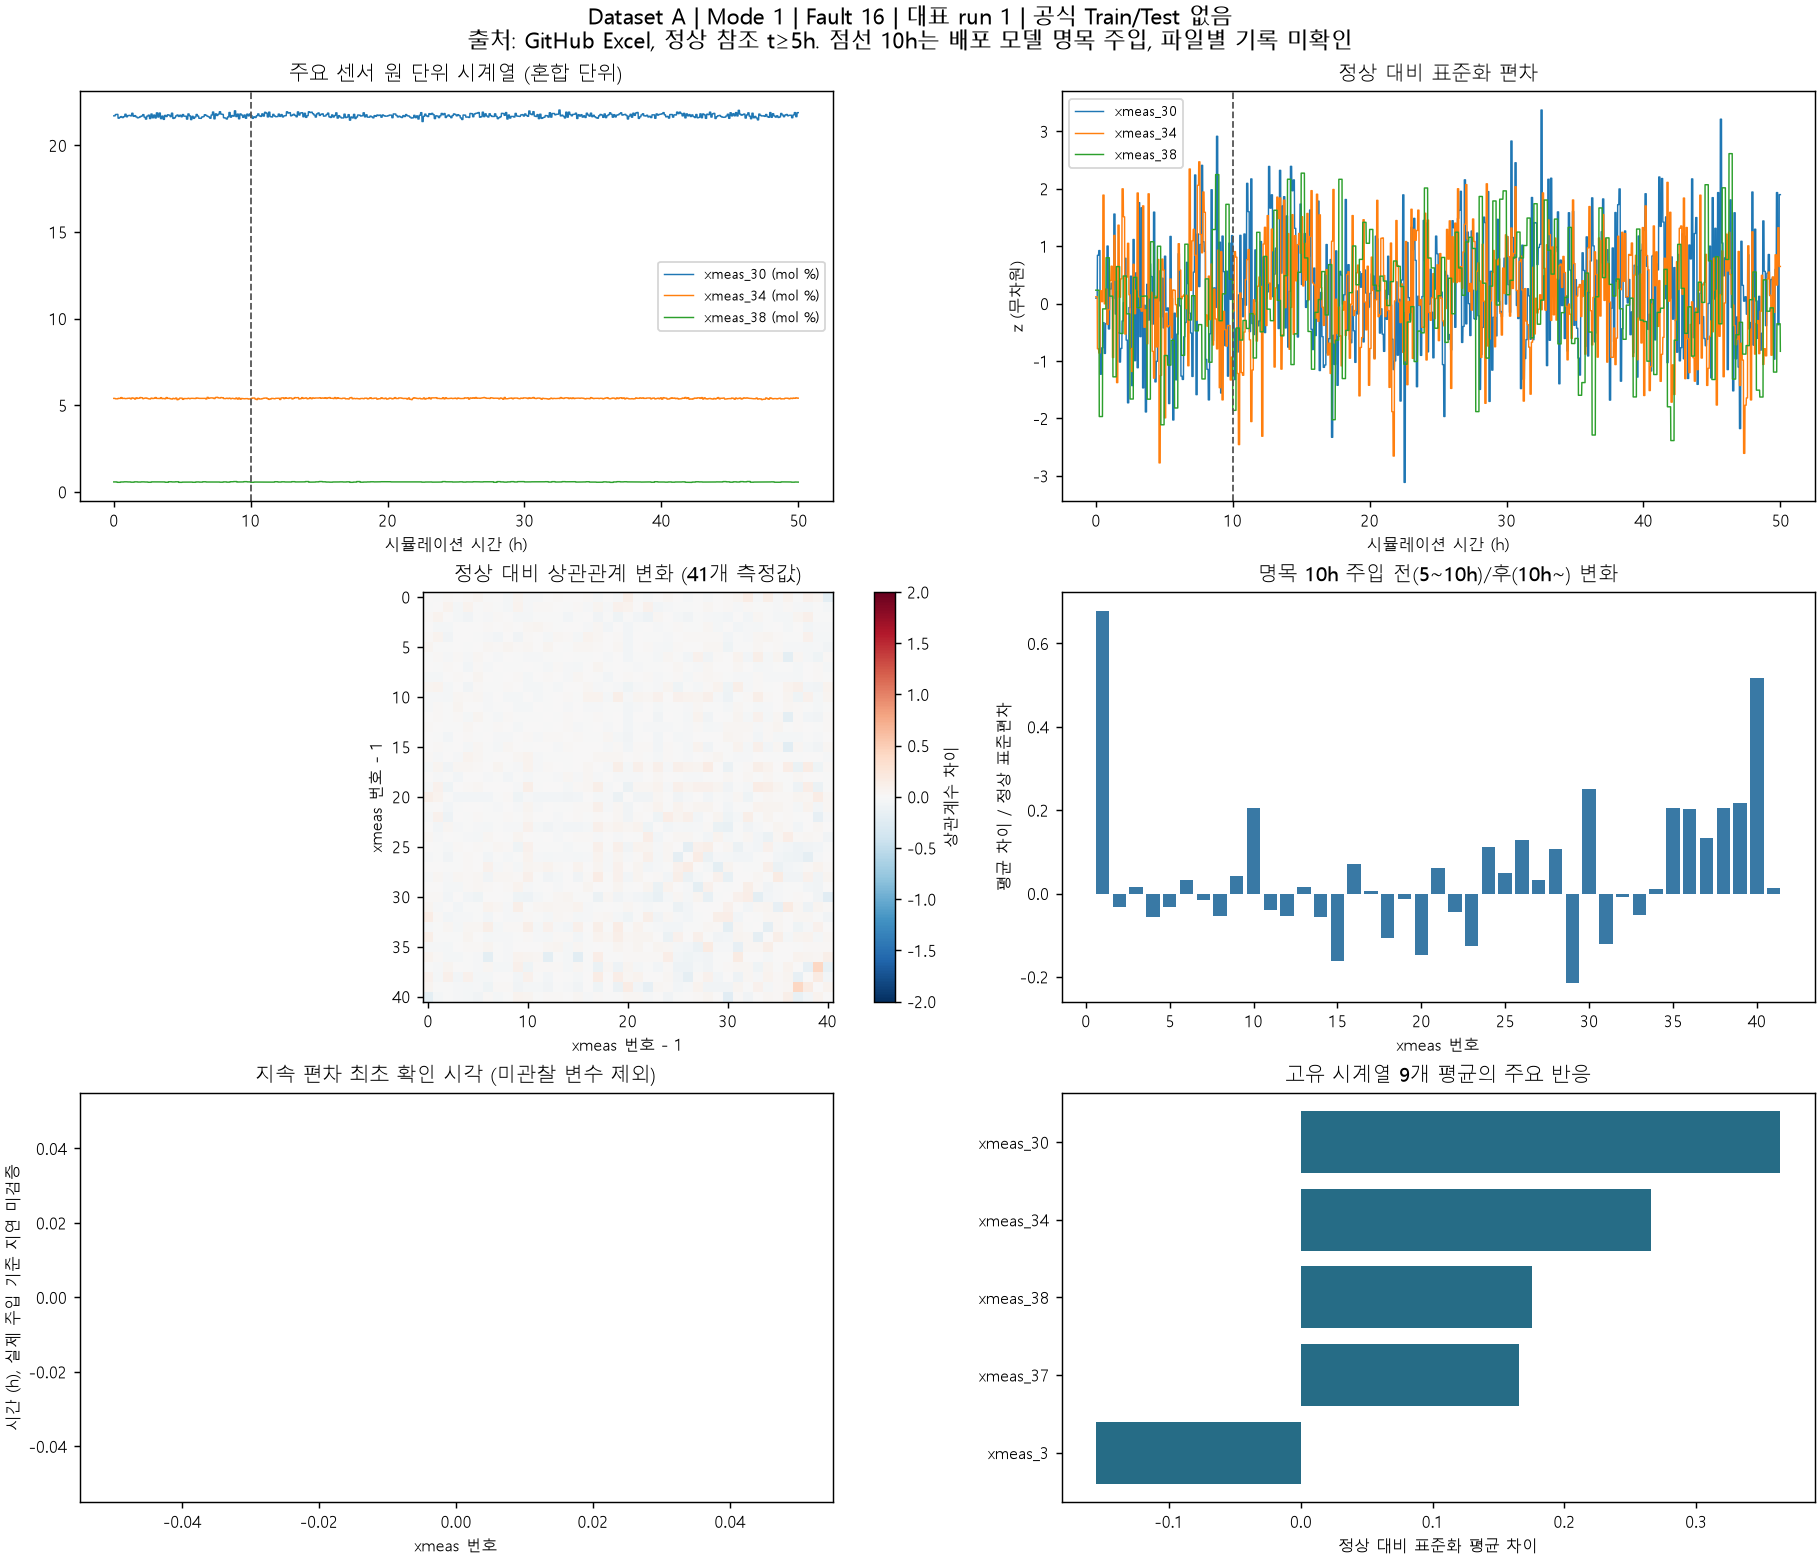

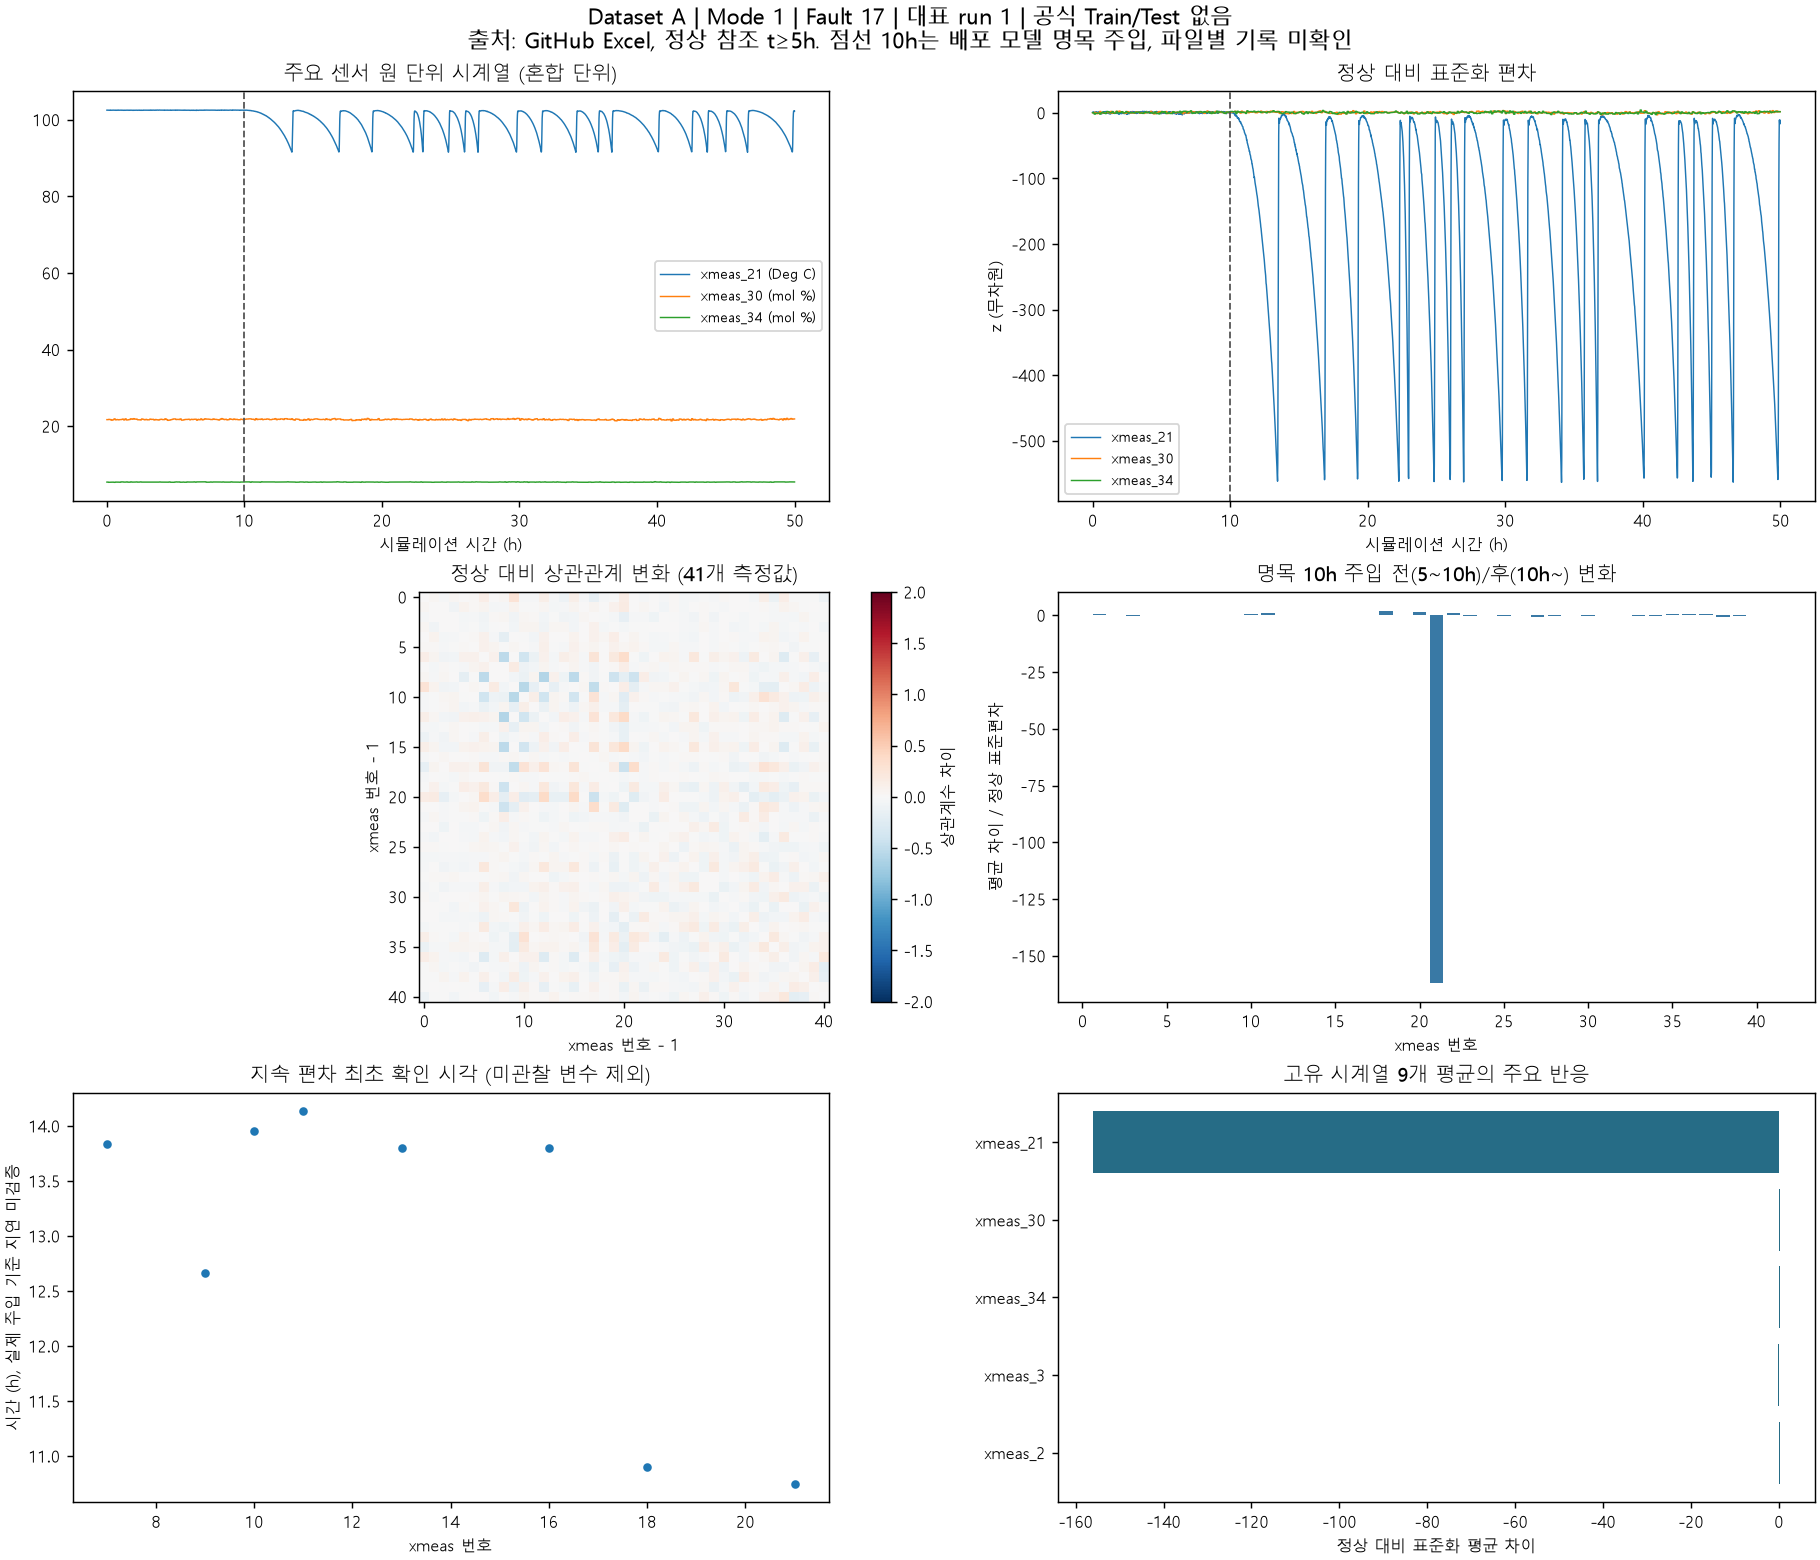

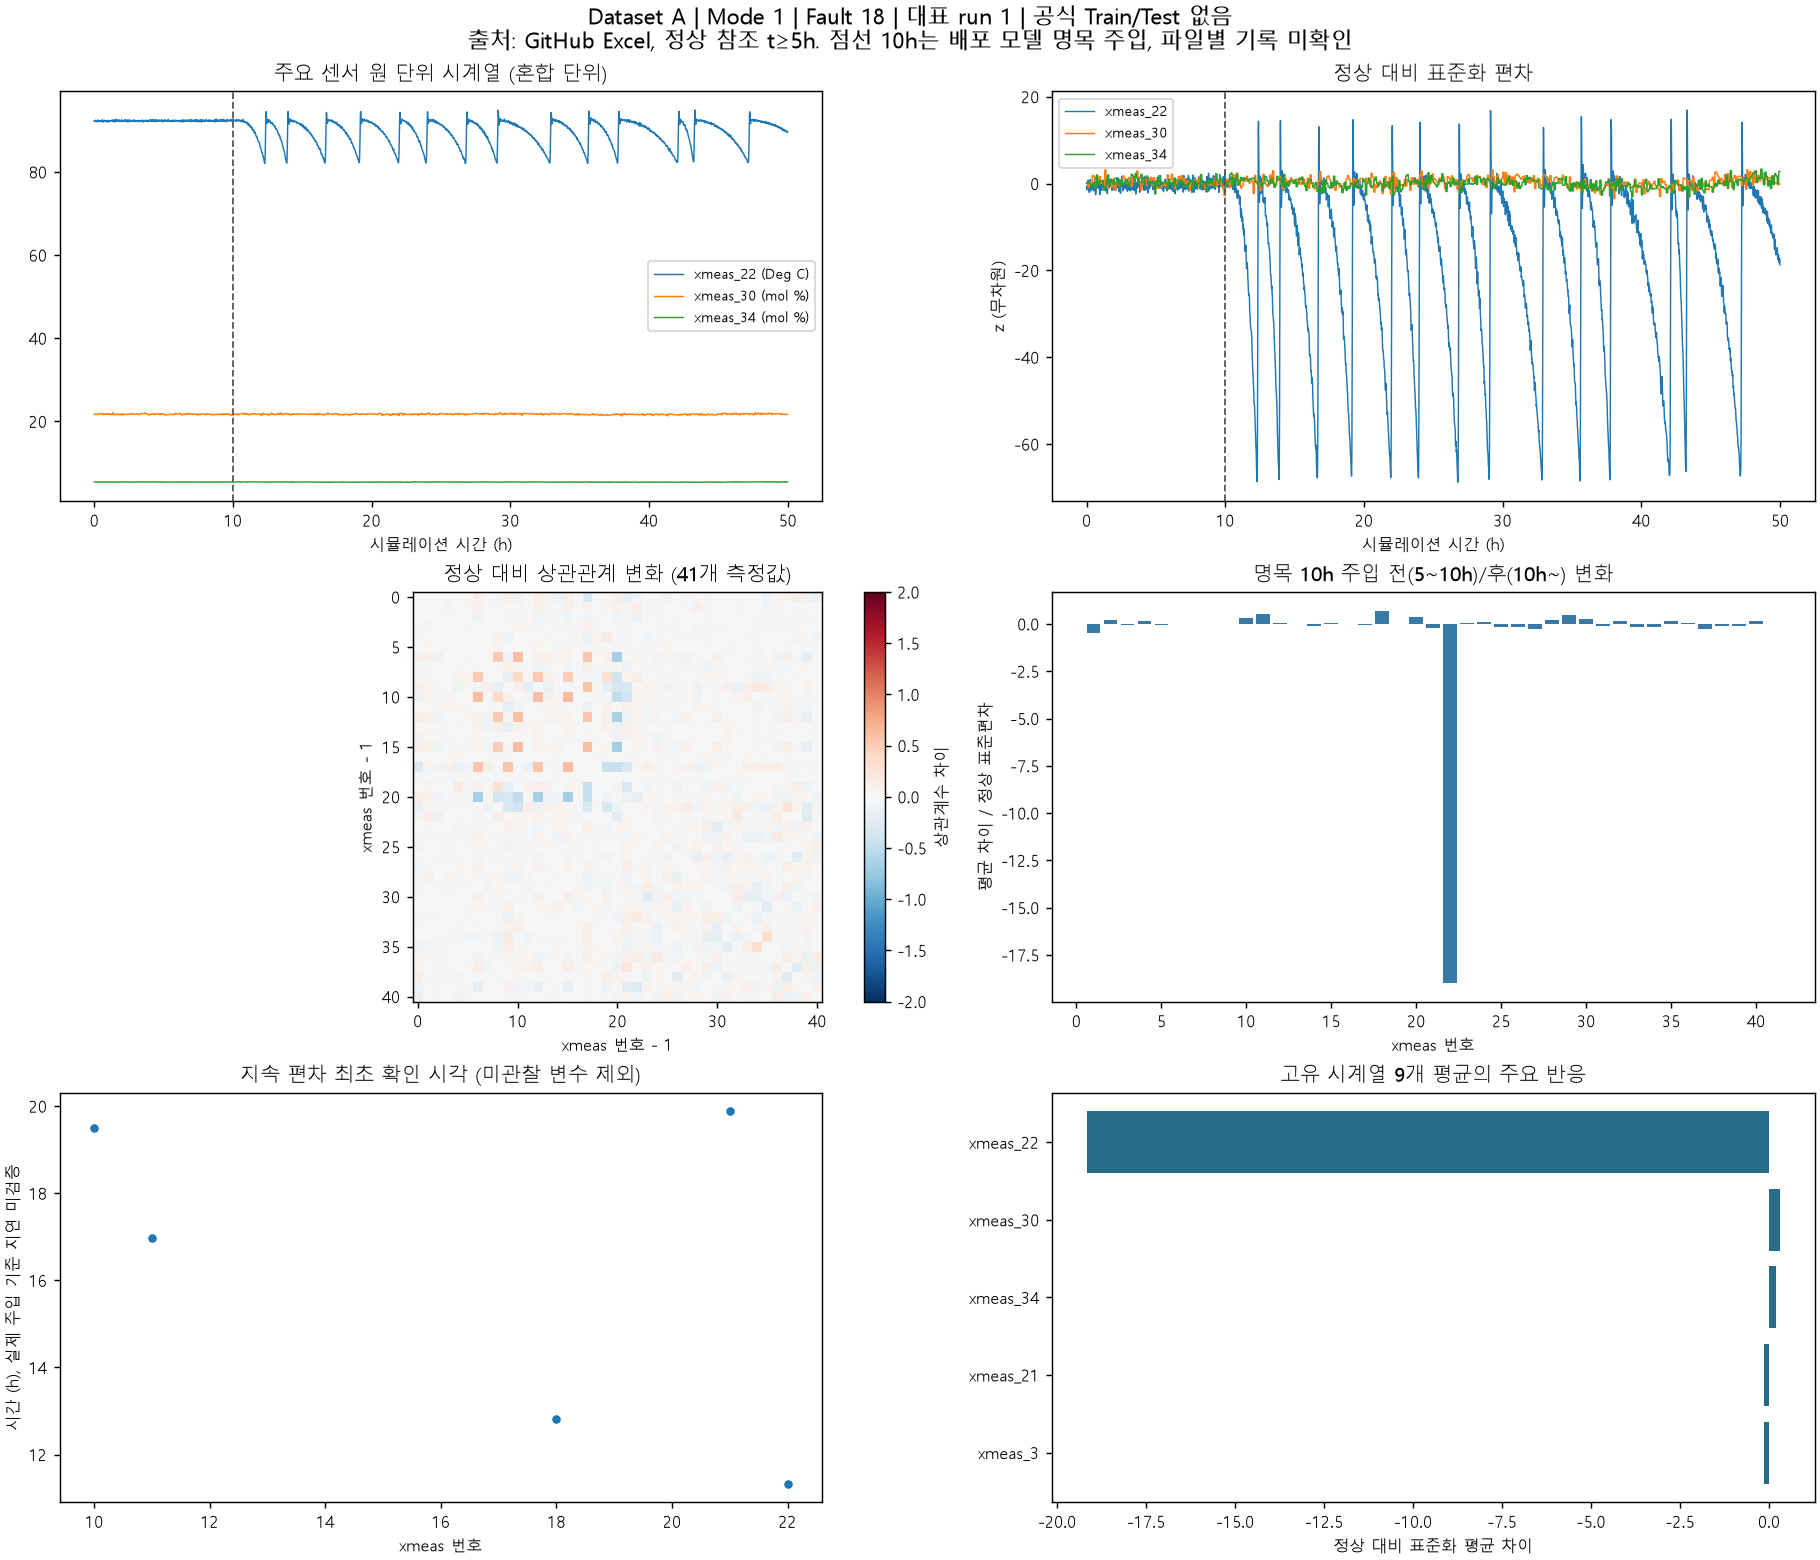

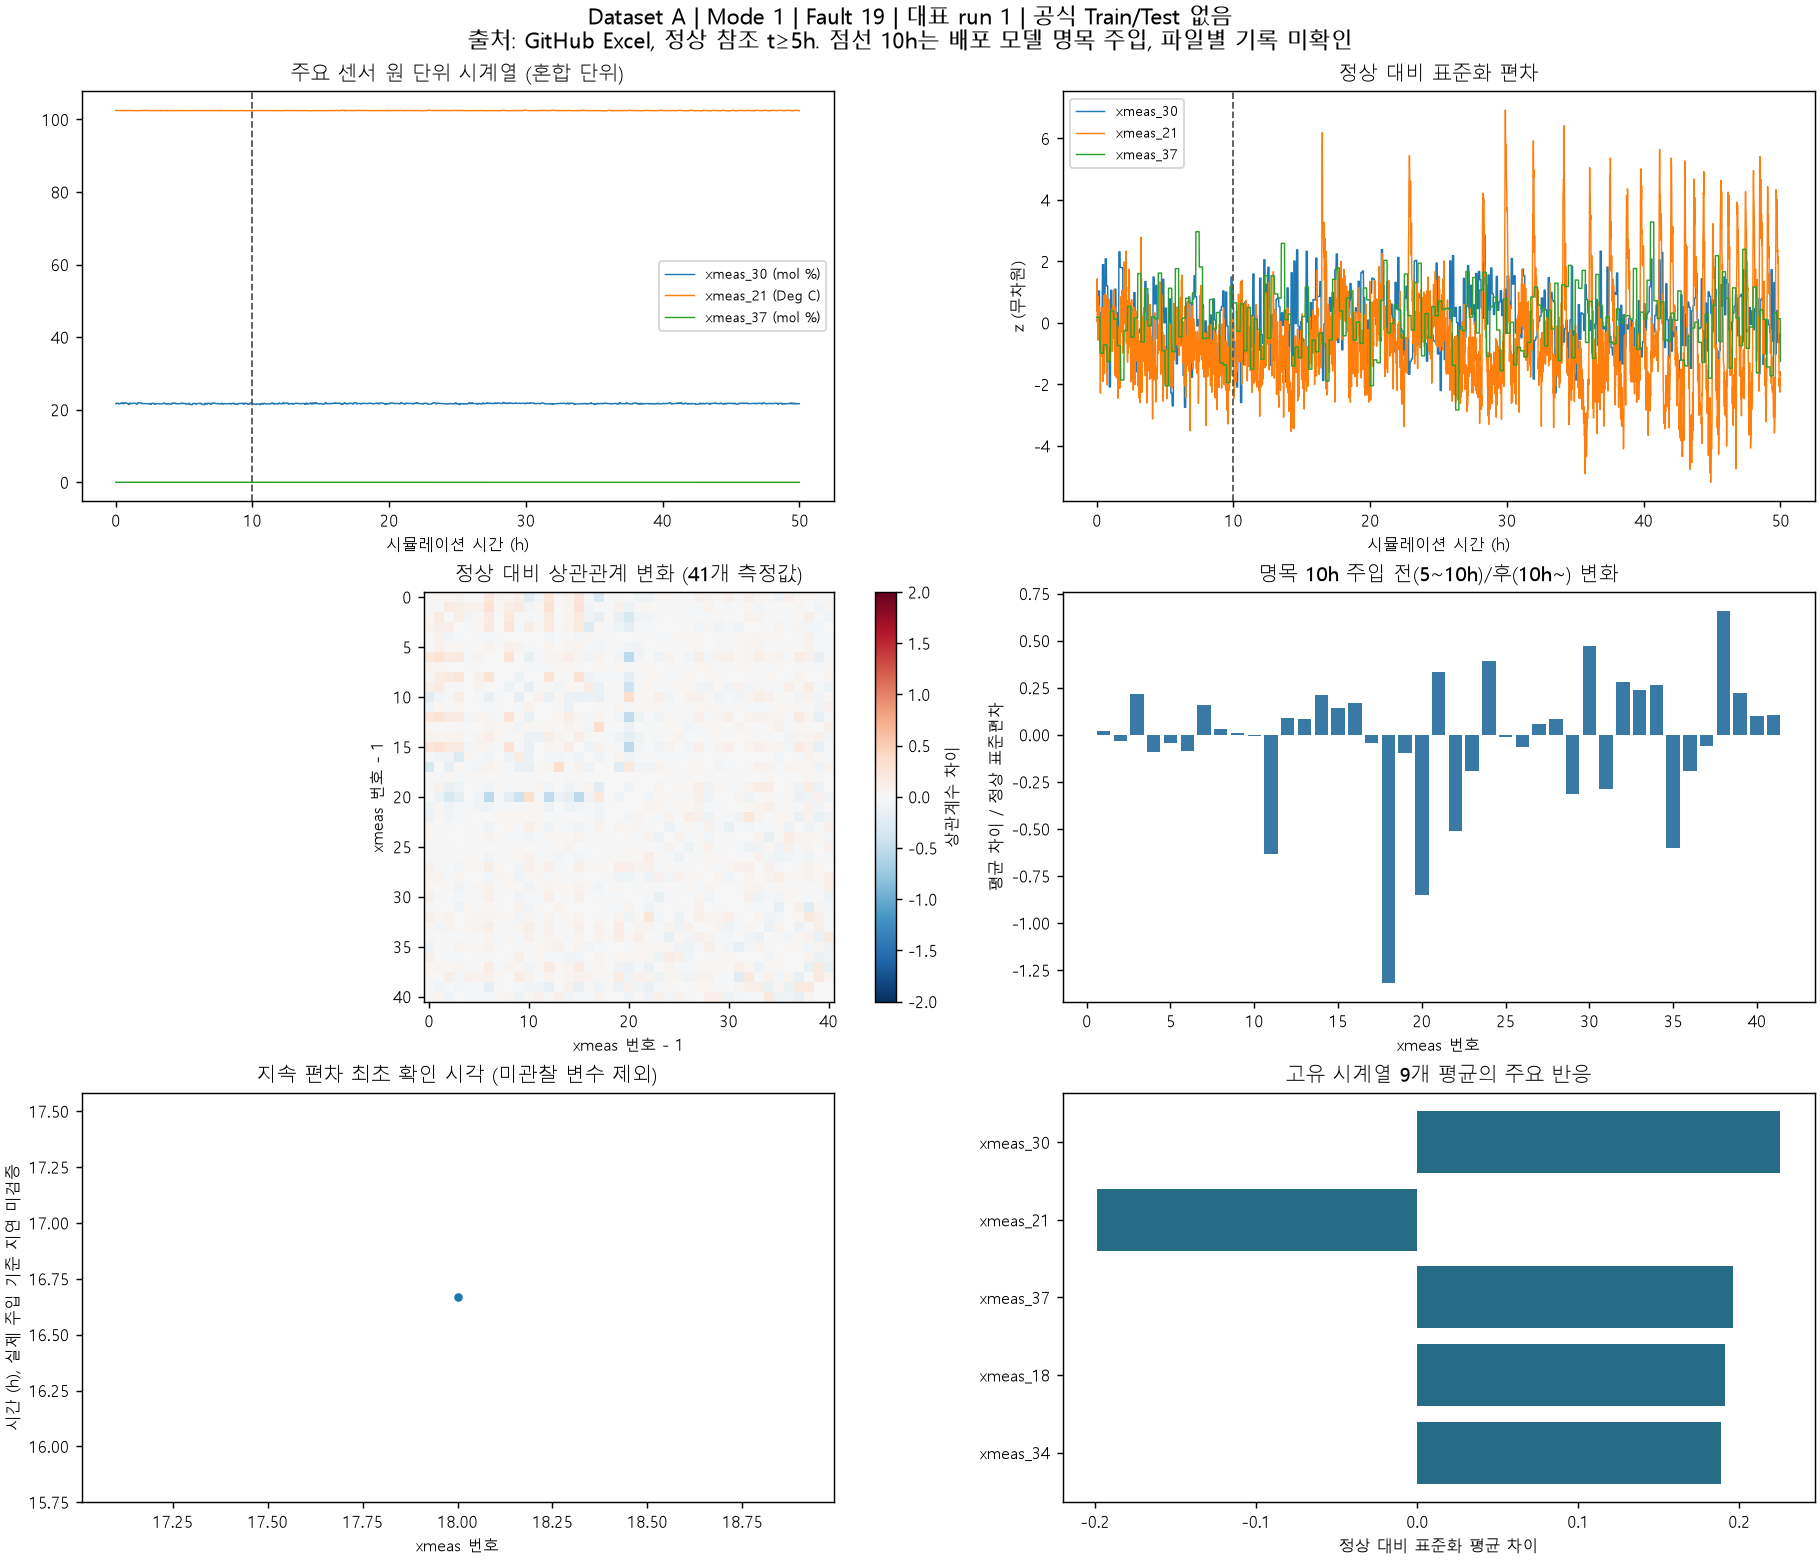

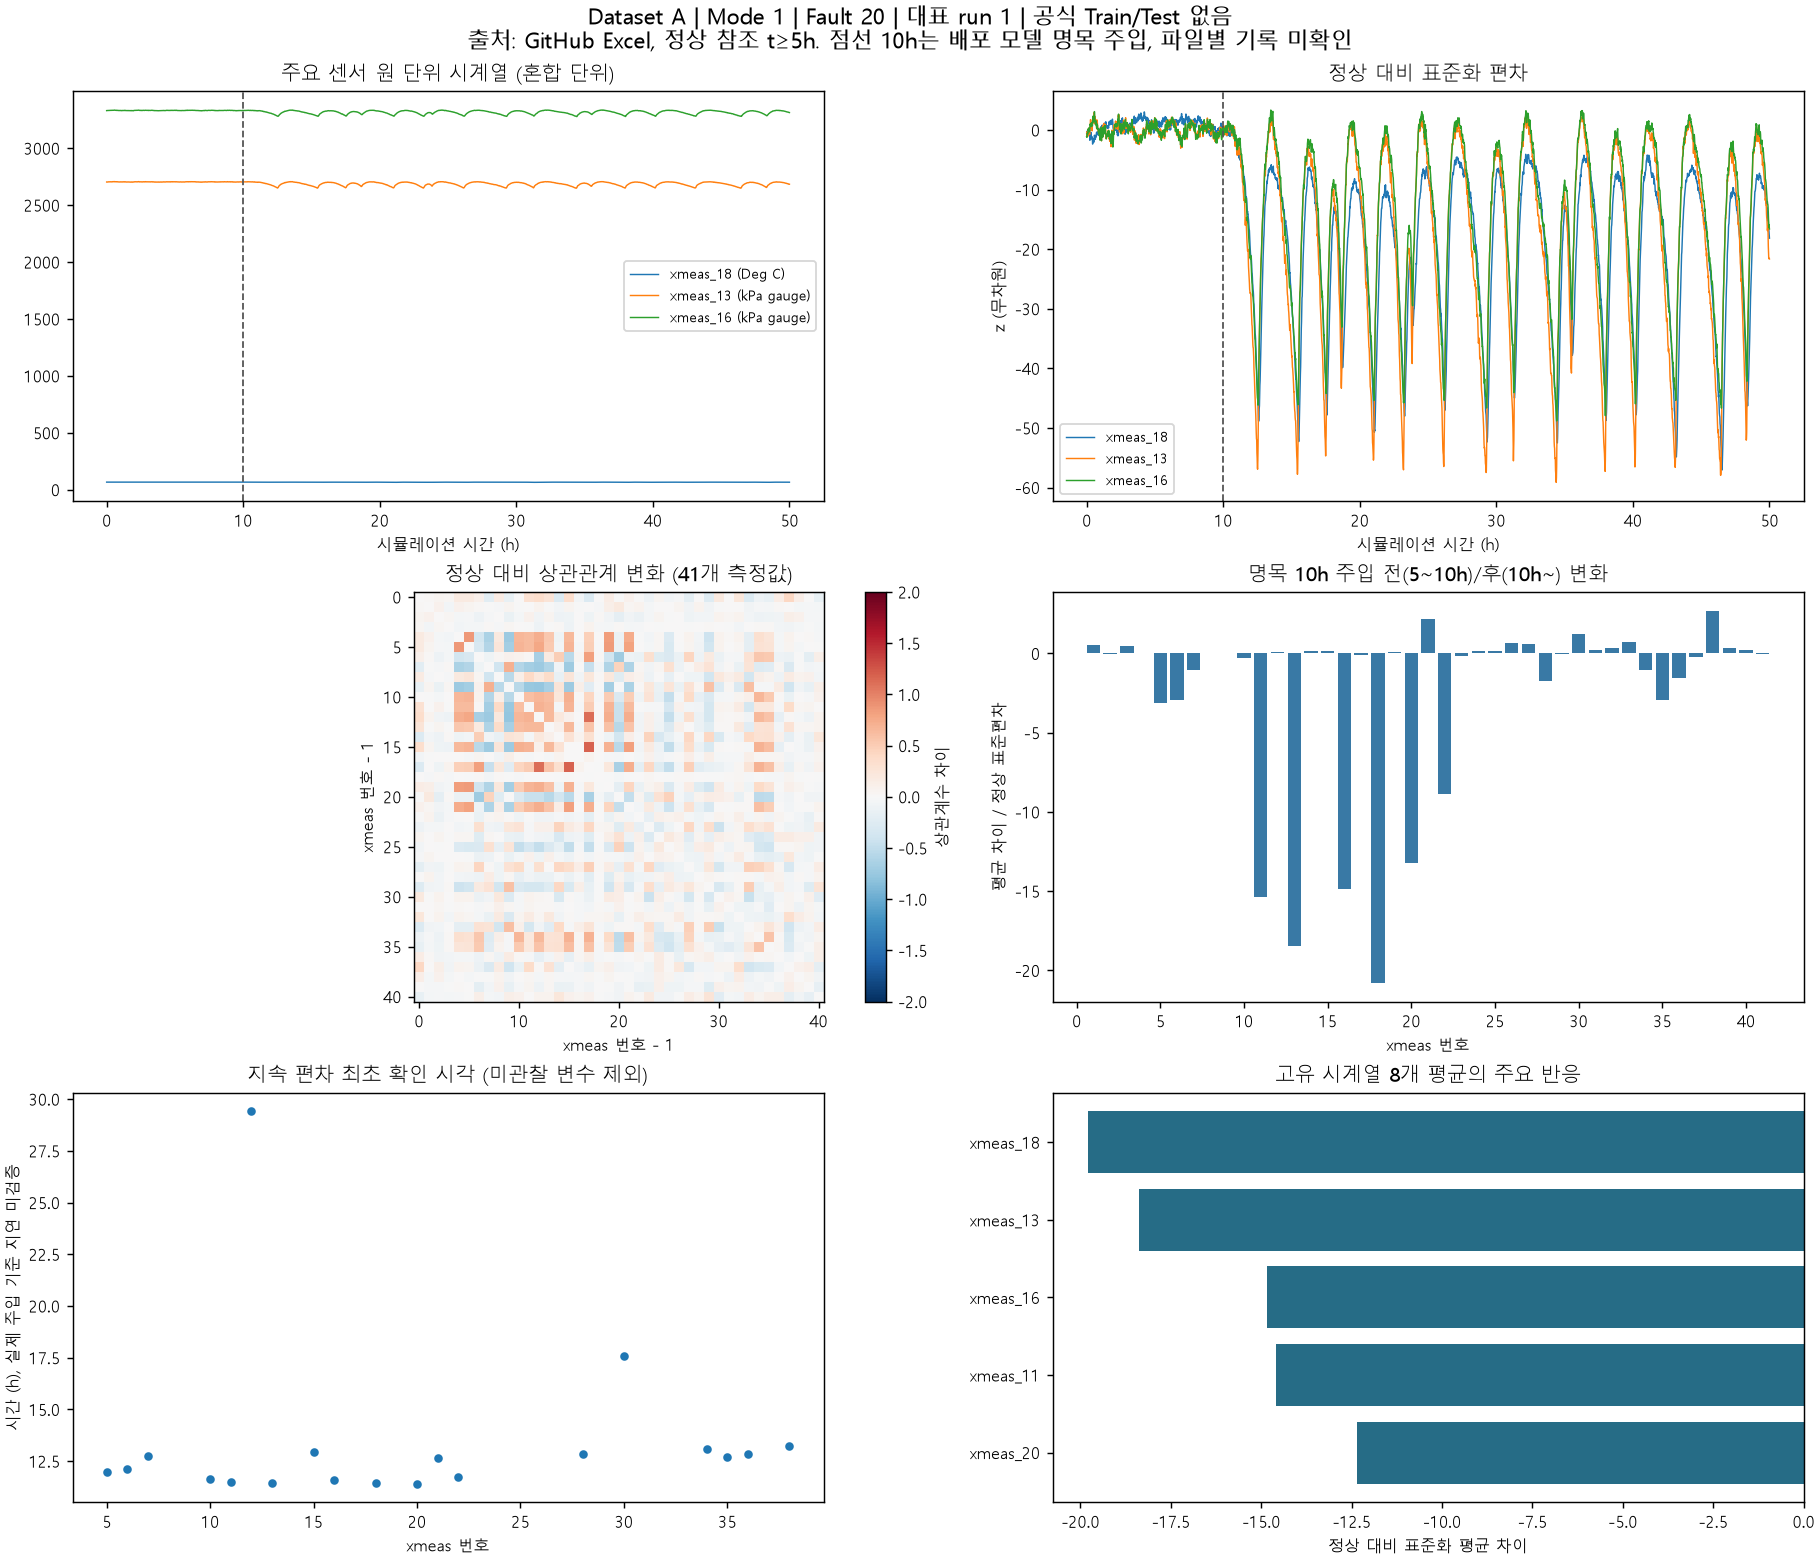

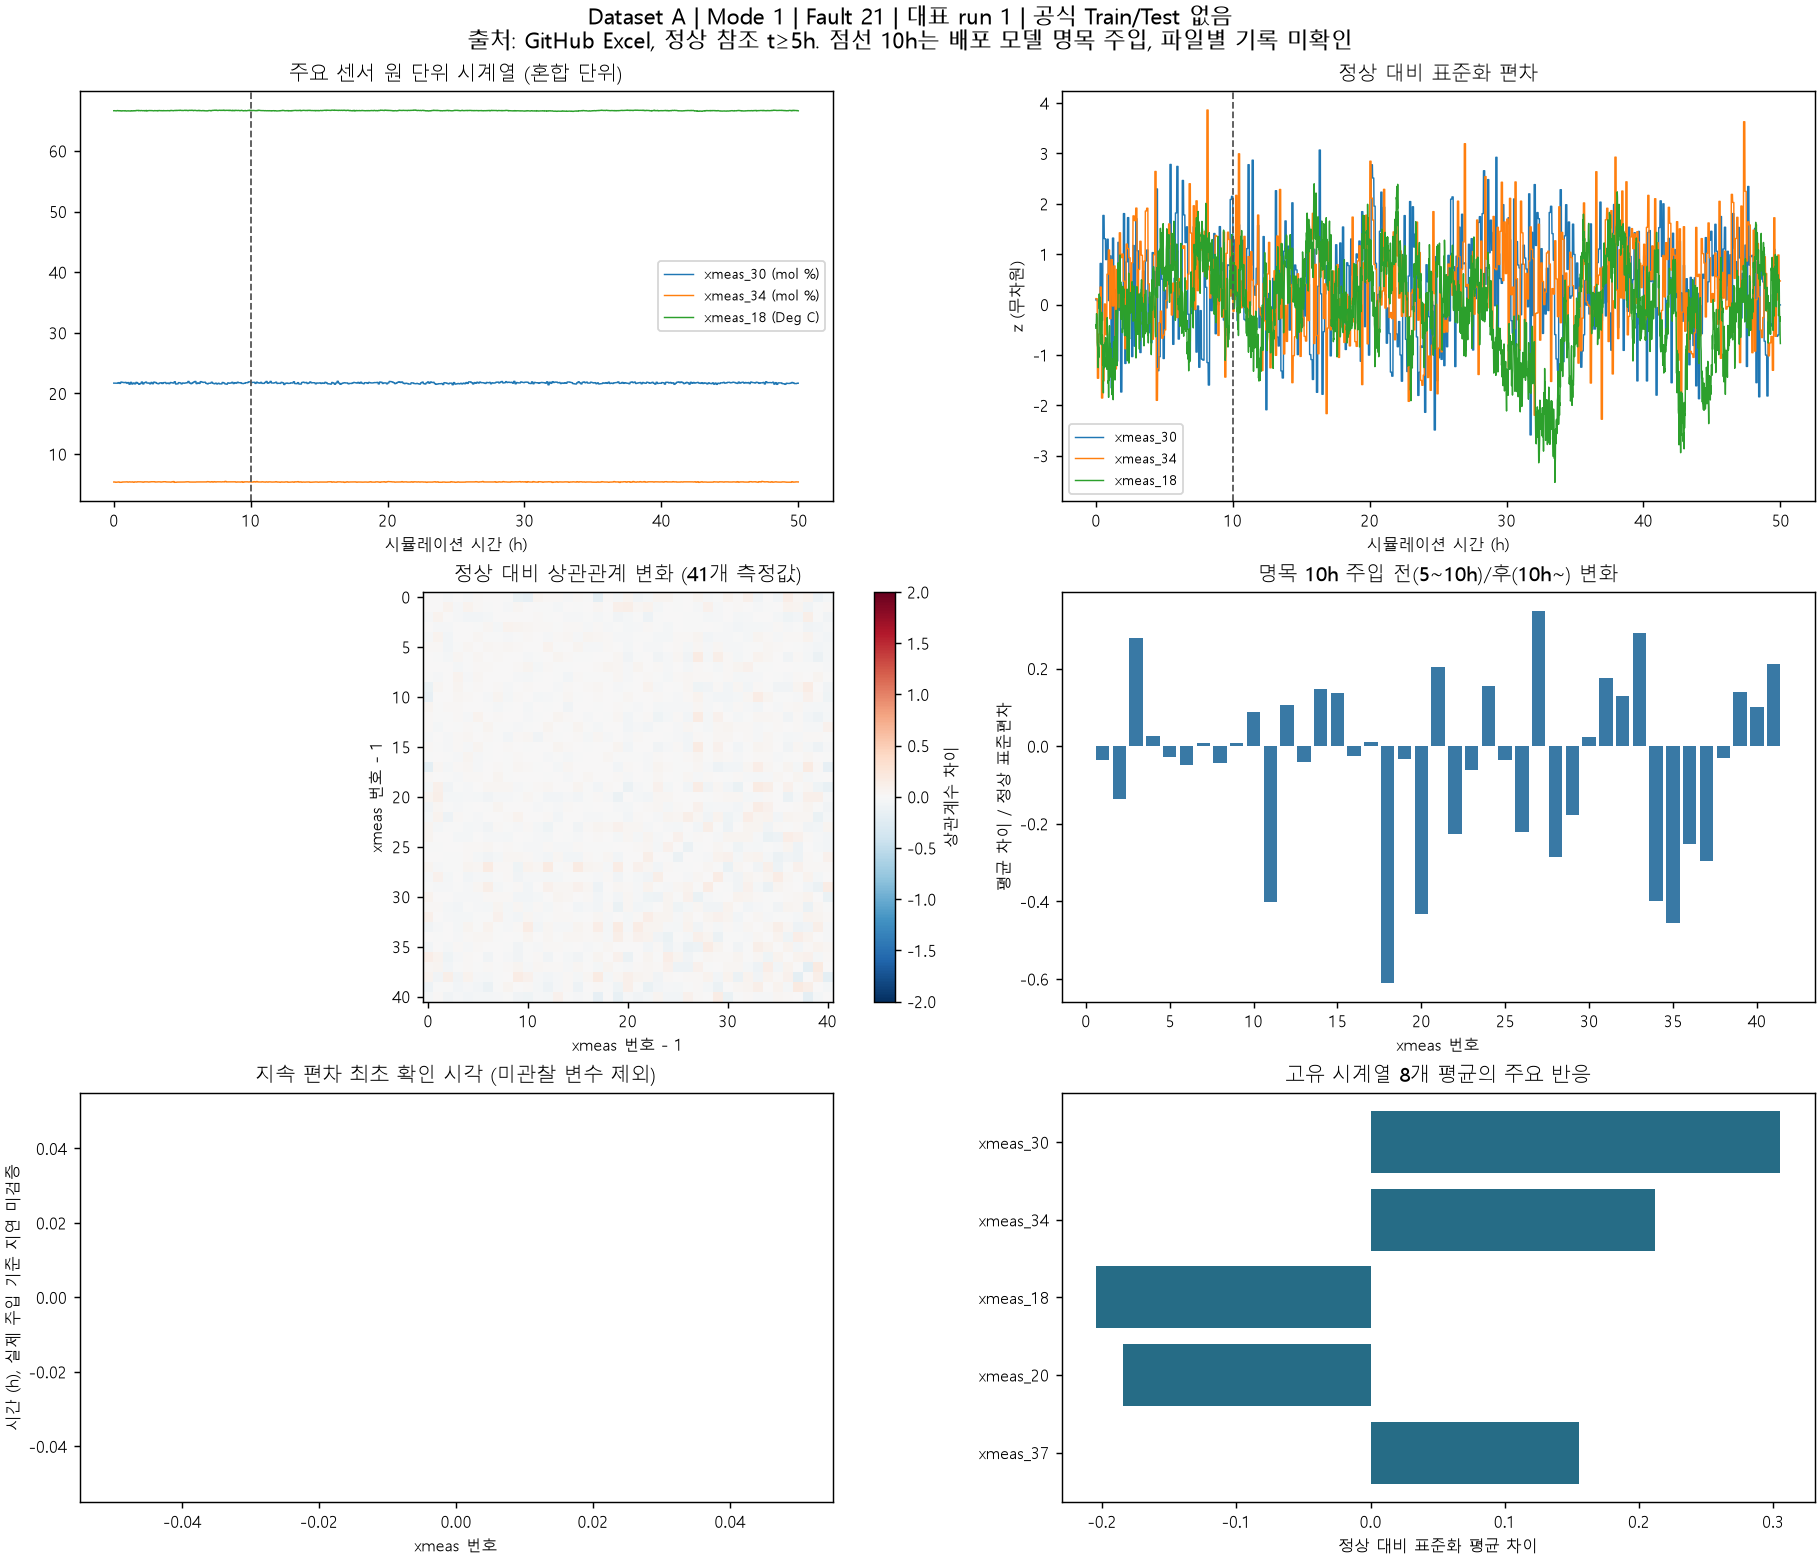

In [2]:
display(Image(filename=str(ROOT / 'reports/figures/fault_response_overview.png')))
for fault in range(1,22):
    display(Image(filename=str(ROOT / f'reports/figures/fault_{fault:02d}_analysis.png')))
